# Baseline · RETECO Track 1 (TEMPO) — sub-tracks 1a y 1b

Corrida del baseline oficial (BM25), su diagnóstico de errores y la **comparación con las cifras del paper de TEMPO**. El análisis de los datos está en [`eda_track1_tempo.ipynb`](eda_track1_tempo.ipynb); explicación paso a paso del baseline en [`BASELINE.md`](../BASELINE.md).

**Requisitos:** haber ejecutado antes el EDA (reutilizamos sus cachés `outputs/eda/corpus_stats/` y `outputs/eda/overlap_jaccard.parquet`). Las matrices BM25, los runs y los embeddings se guardan en `outputs/eda/` (`bm25/`, `runs/`, `dense/`).

**Regla de trabajo:** el diagnóstico y las decisiones de diseño (secciones 1, 2 y 4) usan **train**. La sección 3 es la única que también evalúa el baseline en **dev**, solo para comparar con el paper, que evaluó las 1,730 consultas completas (train + dev). No se toman decisiones de diseño con esas cifras.

| Sección | Contenido |
|---|---|
| 0 | Configuración, cargadores y tablas de apoyo |
| 1 | Baseline oficial: BM25 reimplementado + `pytrec_eval` y runs |
| 2 | Reproducción del baseline y métricas por dominio |
| 3 | Comparación con el paper de TEMPO |
| 4 | Diagnóstico: posición del gold, formulaciones 1b, clase temporal, denso, varianza, fallos |
| 5 | Hallazgos y decisiones para el pipeline |

## 0. Configuración

In [1]:
# --- Librerías estándar ---
import html
import json
import pickle
import random
import re
import time
import warnings
import zlib
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

# --- Librerías de terceros ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytrec_eval
import scipy.sparse as sp
from bs4 import BeautifulSoup
from IPython.display import Markdown, display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Sube por los directorios hasta encontrar la raíz del proyecto.

    La raíz se reconoce porque contiene ``pyproject.toml``. Así el notebook
    funciona igual si se lanza desde ``notebooks/`` o desde la raíz.

    Args:
        start: directorio desde el que empezar a buscar.

    Returns:
        Ruta absoluta de la raíz del proyecto.

    Raises:
        FileNotFoundError: si no hay ningún ``pyproject.toml`` hacia arriba.
    """
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("No se encontró pyproject.toml en ningún directorio padre")


ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "RETECO-SemEval2027"
T1_DIR = DATA_DIR / "track1_tempo"

# Caché de resultados intermedios costosos (estadísticas del corpus, matrices BM25,
# runs y embeddings). Borrar un archivo obliga a recalcularlo.
CACHE_DIR = ROOT / "outputs" / "eda"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "dev")
SPLIT = "train"            # split sobre el que se hace TODO el análisis
SEED = 20270101            # misma semilla que el split oficial, por coherencia
DOMAINS = sorted(p.name for p in T1_DIR.iterdir() if p.is_dir())

random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print(f"Raíz del proyecto: {ROOT}")
print(f"{len(DOMAINS)} dominios: {', '.join(DOMAINS)}")

Raíz del proyecto: /Users/valentinacruz/RETECO
13 dominios: bitcoin, cardano, economics, genealogy, history, hsm, iota, law, monero, politics, quant, travel, workplace


In [3]:
# --- Estilo de las gráficas ---
# Paleta categórica fija (validada para daltonismo); el orden nunca se cicla.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
C_GOLD, C_NOGOLD, C_THIRD = PALETTE[0], PALETTE[1], PALETTE[2]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False,
})


def style_ax(ax, title=None, xlabel=None, ylabel=None):
    """Aplica título y etiquetas a un eje de matplotlib de forma homogénea.

    Args:
        ax: eje de matplotlib.
        title: título del gráfico (opcional).
        xlabel: etiqueta del eje x (opcional).
        ylabel: etiqueta del eje y (opcional).

    Returns:
        El mismo eje, para poder encadenar llamadas.
    """
    if title:
        ax.set_title(title, loc="left")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax


def add_total_row(df: pd.DataFrame, all_cols: tuple = ()) -> pd.DataFrame:
    """Añade una fila ``TOTAL`` con la suma de las columnas numéricas.

    Las columnas booleanas de ``all_cols`` no se suman: en la fila TOTAL valen
    ``True`` solo si todas las filas son ``True``.

    Args:
        df: tabla con una fila por dominio.
        all_cols: columnas booleanas que se agregan con ``all()``.

    Returns:
        Copia de la tabla con la fila ``TOTAL`` al final.
    """
    out = df.copy()
    total = out.drop(columns=list(all_cols)).sum(numeric_only=True).to_dict()
    total.update({c: bool(out[c].all()) for c in all_cols})
    out.loc["TOTAL"] = pd.Series(total)
    return out

### 0.1 Cargadores reutilizables

Equivalen al `src/data.py` propuesto en el plan: leen cada tipo de archivo de un dominio. Los documentos se leen **en streaming** (generador) porque el corpus completo ocupa ~3 GB.

In [4]:
def read_jsonl(path: Path) -> list[dict]:
    """Lee un archivo JSON Lines completo.

    Args:
        path: ruta al ``.jsonl``.

    Returns:
        Lista de diccionarios, uno por línea no vacía.
    """
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def iter_documents(domain: str):
    """Recorre el corpus de un dominio sin cargarlo entero en memoria.

    Args:
        domain: nombre del dominio (p. ej. ``"law"``).

    Yields:
        Diccionarios ``{"id": str, "content": str}``.
    """
    with open(T1_DIR / domain / "documents.jsonl", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                yield json.loads(line)


def load_examples(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga las consultas de la sub-tarea 1a: ``{id, query, gold_ids, gold_answers}``."""
    return read_jsonl(T1_DIR / domain / f"examples_{split}.jsonl")


def load_steps(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga las consultas descompuestas en pasos (1b).

    Cada registro es ``{id, query, steps: [{step_id, step, step_instruction, gold_ids}]}``.
    """
    return read_jsonl(T1_DIR / domain / f"steps_{split}.jsonl")


def load_guidance(domain: str, split: str = SPLIT) -> list[dict]:
    """Carga los metadatos temporales: ``{id, query_guidance, gold_passage_annotations}``."""
    return read_jsonl(T1_DIR / domain / f"guidance_{split}.jsonl")


def load_qrels(domain: str, split: str = SPLIT, subtrack: str = "1a") -> dict[str, dict[str, int]]:
    """Carga los juicios de relevancia en formato TREC (``qid 0 docid rel``).

    Args:
        domain: nombre del dominio.
        split: ``"train"`` o ``"dev"``.
        subtrack: ``"1a"`` (qid = id de consulta) o ``"1b"`` (qid = step_id).

    Returns:
        Diccionario anidado ``{qid: {docid: relevancia}}``, el formato que espera
        ``pytrec_eval``.
    """
    name = f"qrels_{split}.txt" if subtrack == "1a" else f"qrels_steps_{split}.txt"
    qrels: dict[str, dict[str, int]] = defaultdict(dict)
    with open(T1_DIR / domain / name, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                qid, _, docid, rel = line.split()
                qrels[qid][docid] = int(rel)
    return dict(qrels)


def count_qrels_lines(domain: str, split: str, subtrack: str) -> int:
    """Cuenta las líneas no vacías de un archivo de qrels."""
    name = f"qrels_{split}.txt" if subtrack == "1a" else f"qrels_steps_{split}.txt"
    with open(T1_DIR / domain / name, encoding="utf-8") as f:
        return sum(1 for line in f if line.strip())


def load_duplicate_map(domain: str) -> dict[str, str]:
    """Carga el mapa de deduplicación v1.1: ``{id eliminado: id conservado}``."""
    with open(T1_DIR / domain / "duplicate_map.json", encoding="utf-8") as f:
        return json.load(f)


def load_manifest() -> dict:
    """Carga ``split_manifest.json`` (semilla, conteos e IDs exactos de cada split)."""
    with open(DATA_DIR / "split_manifest.json", encoding="utf-8") as f:
        return json.load(f)


def gold_ids_for(domain: str, split: str) -> set[str]:
    """Devuelve todos los documentos relevantes (1a ∪ 1b) de un dominio y split."""
    ids = set()
    for subtrack in ("1a", "1b"):
        for docs in load_qrels(domain, split, subtrack).values():
            ids.update(docs)
    return ids


MANIFEST = load_manifest()

### 0.2 Utilidades de texto

Funciones compartidas por varias secciones: limpieza del HTML de las consultas y extracción de rasgos temporales con expresiones regulares. Las regex son una aproximación rápida (por ejemplo, `YEAR_RE` también captura cantidades como "1500 USD"); sirven para comparar grupos entre sí, no como medida exacta.

In [5]:
# Años plausibles (1500–2039). Se excluyen números pegados a otros dígitos, comas o puntos
# decimales para no capturar cantidades como 1,999 o 2000.5.
YEAR_RE = re.compile(r"(?<![\d.,$])\b(1[5-9]\d\d|20[0-3]\d)\b(?![.,]\d)")
MONTH_RE = re.compile(
    r"\b(january|february|march|april|june|july|august|september|october|november|december|"
    r"jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec)\.?\s+\d{1,4}\b",
    re.IGNORECASE,
)
DATE_RE = re.compile(r"\b(\d{4}-\d{2}-\d{2}|\d{1,2}/\d{1,2}/\d{2,4})\b")
DECADE_RE = re.compile(r"\b(1[5-9]\d0s|20[0-3]0s|'\d0s|\d{1,2}(st|nd|rd|th)\s+century)\b", re.IGNORECASE)
RELATIVE_RE = re.compile(
    r"\b(before|after|since|until|till|during|ago|prior to|earlier|later|previously|"
    r"formerly|nowadays|currently|recently|today|yesterday|now|"
    r"(last|next|this|past|previous|coming)\s+(year|month|week|decade|century|day)s?)\b",
    re.IGNORECASE,
)
RANGE_RE = re.compile(
    r"\b(between\s+\d{3,4}\s+and\s+\d{3,4}|from\s+\d{3,4}\s+to\s+\d{3,4}|\d{4}\s*[-–]\s*\d{2,4})\b",
    re.IGNORECASE,
)
RECENCY_RE = re.compile(r"\b(recent(ly)?|current(ly)?|latest|nowadays|now|today|still|anymore|up to date|outdated)\b",
                        re.IGNORECASE)
HTML_TAG_RE = re.compile(r"</?(p|div|a|br|li|ul|ol|span|table|tr|td|h[1-6]|code|pre|em|strong|blockquote)\b[^>]*>",
                         re.IGNORECASE)
MARKDOWN_RE = re.compile(r"(^#{1,6}\s|\*\*[^*\n]+\*\*|\[[^\]\n]+\]\([^)\s]+\)|^```)", re.MULTILINE)
WORD_RE = re.compile(r"\w+")


def text_features(text: str) -> dict:
    """Calcula rasgos superficiales y temporales de un texto.

    Se usan para describir el corpus y para comparar documentos gold con no-gold.

    Args:
        text: contenido del documento.

    Returns:
        Diccionario con longitud (caracteres y palabras), conteos de expresiones
        temporales (años, fechas, meses con número, décadas, expresiones relativas),
        indicadores de formato (HTML, markdown) y fracción de caracteres no ASCII.
    """
    n_chars = len(text)
    # Caracteres no ASCII = los que desaparecen al codificar a ASCII ignorando errores (rápido, en C).
    n_non_ascii = n_chars - len(text.encode("ascii", "ignore"))
    return {
        "n_chars": n_chars,
        "n_words": len(WORD_RE.findall(text)),
        "n_years": len(YEAR_RE.findall(text)),
        "n_dates": len(DATE_RE.findall(text)),
        "n_months": len(MONTH_RE.findall(text)),
        "n_decades": len(DECADE_RE.findall(text)),
        "n_relative": len(RELATIVE_RE.findall(text)),
        "has_html": bool(HTML_TAG_RE.search(text)),
        "has_markdown": bool(MARKDOWN_RE.search(text)),
        "non_ascii_frac": n_non_ascii / n_chars if n_chars else 0.0,
    }


def split_query(raw: str) -> tuple[str, str]:
    """Separa una consulta estilo StackExchange en título y cuerpo, sin HTML.

    Las consultas llegan como ``"<título>\n<p>cuerpo html</p>..."``: la primera línea
    es el título en texto plano y el resto es HTML.

    Args:
        raw: consulta original.

    Returns:
        Tupla ``(título, cuerpo)`` con el HTML eliminado, las entidades decodificadas
        y los espacios normalizados.
    """
    title, _, body_html = raw.partition("\n")
    body = BeautifulSoup(body_html, "html.parser").get_text(" ")
    norm = lambda s: re.sub(r"\s+", " ", html.unescape(s)).strip()
    return norm(title), norm(body)


def clean_query(raw: str) -> str:
    """Devuelve la consulta como texto plano: ``"título. cuerpo"``."""
    title, body = split_query(raw)
    return f"{title}. {body}" if body else title


def temporal_query_flags(text: str) -> dict:
    """Marca qué tipos de expresión temporal explícita contiene una consulta.

    Args:
        text: consulta ya limpia (sin HTML).

    Returns:
        Diccionario de booleanos: año, fecha, década/siglo, expresión relativa
        (before/after/since...), recencia (recently/currently...) y rango de años.
    """
    return {
        "año": bool(YEAR_RE.search(text)),
        "fecha": bool(DATE_RE.search(text) or MONTH_RE.search(text)),
        "década/siglo": bool(DECADE_RE.search(text)),
        "relativa": bool(RELATIVE_RE.search(text)),
        "recencia": bool(RECENCY_RE.search(text)),
        "rango": bool(RANGE_RE.search(text)),
    }


# Formatos de ID observados en el corpus:
#   corto: <dominio>/<hash8>_<n>.txt
#   largo: <dominio>/<número>_<hash16>_<n>.txt
ID_RE = re.compile(
    r"^(?P<dom>[^/]+)/(?:(?P<qnum>\d+)_(?P<hash16>[0-9a-f]{16})|(?P<hash8>[0-9a-f]{8}))_(?P<num>\d+)\.txt$"
)


def parse_doc_id(doc_id: str) -> dict:
    """Descompone un ID de documento en sus partes.

    Args:
        doc_id: ID tal como aparece en ``documents.jsonl``.

    Returns:
        Diccionario con ``id_format`` (``"corto"``, ``"largo"`` u ``"otro"``),
        ``qnum`` (prefijo numérico de los IDs largos, si existe) y ``num`` (sufijo).
    """
    m = ID_RE.match(doc_id)
    if not m:
        return {"id_format": "otro", "qnum": None, "num": None}
    return {
        "id_format": "largo" if m["qnum"] else "corto",
        "qnum": m["qnum"],
        "num": int(m["num"]),
    }


print(split_query("When do laws apply?\n<p>Building <em>regs</em> &amp; tenancies.</p>\n"))
print(temporal_query_flags("What changed in Bitcoin Core since 2017, before the recent fork?"))

('When do laws apply?', 'Building regs & tenancies.')
{'año': True, 'fecha': False, 'década/siglo': False, 'relativa': True, 'recencia': True, 'rango': False}


### 0.3 Cachés y tablas de apoyo (del EDA)

- `load_texts` lee la caché de textos que genera el EDA (gold y muestra del 1 % de cada dominio).
- `queries` y `guid` son las tablas de consultas y de guidance del EDA (secciones 3 y 5 de ese notebook), reducidas a las columnas que usa el diagnóstico.
- `overlap` es el Jaccard consulta↔gold que calcula la sección 3.5 del EDA.

In [6]:
import pickle
import zlib

STATS_DIR = CACHE_DIR / "corpus_stats"
DENSE_MODEL = "BAAI/bge-small-en-v1.5"


def load_texts(domain: str) -> dict[str, str]:
    """Devuelve ``{id: texto}`` de los gold y de la muestra del 1 % (caché del EDA)."""
    with open(STATS_DIR / f"{domain}_texts.pkl", "rb") as f:
        return pickle.load(f)


def query_number(qid: str) -> str:
    """Devuelve el número de pregunta de StackExchange de un id de consulta (``"112346_808"`` → ``"112346"``)."""
    return qid.split("_")[0]


# --- Consultas (1a) con su limpieza y si tienen alguna expresión temporal explícita ---
q_rows = []
for dom in DOMAINS:
    for r in load_examples(dom):
        title, _ = split_query(r["query"])
        clean = clean_query(r["query"])
        q_rows.append({"domain": dom, "id": r["id"], "title": title, "clean": clean,
                       "words_clean": len(WORD_RE.findall(clean)), "n_gold": len(r["gold_ids"])})
queries = pd.DataFrame(q_rows)
flags = pd.DataFrame([temporal_query_flags(t) for t in queries["clean"]], index=queries.index)
queries["alguna"] = flags.any(axis=1)

# --- Guidance temporal: metadatos de cada consulta ---
g_rows = []
for dom in DOMAINS:
    for g in load_guidance(dom):
        qg = g["query_guidance"]
        g_rows.append({"domain": dom, "qid": g["id"], "temporal_intent": qg["temporal_intent"],
                       "clase_primaria": qg["temporal_reasoning_class_primary"],
                       "granularidad": qg["expected_granularity"]})
guid = pd.DataFrame(g_rows)
# Las cadenas vacías se etiquetan explícitamente; la granularidad (texto libre) agrupa en "otras" los valores raros.
for col in ["temporal_intent", "clase_primaria", "granularidad"]:
    guid[col] = guid[col].replace("", "(vacío)")
gran_counts = guid["granularidad"].value_counts()
guid["granularidad_top"] = guid["granularidad"].where(guid["granularidad"].map(gran_counts) >= 15, "otras")

overlap = pd.read_parquet(CACHE_DIR / "overlap_jaccard.parquet")
print(f"{len(queries)} consultas, {len(guid)} registros de guidance, {len(overlap):,} pares de solapamiento")

1211 consultas, 1211 registros de guidance, 14,763 pares de solapamiento


## 1. Baseline oficial: BM25 reimplementado + `pytrec_eval`

El baseline oficial (`starter_kit/official_baseline.py`) **no** es el BM25 de un índice Lucene estándar. Usa:

- el analizador de Lucene de Pyserini (minúsculas, *stopwords*, Porter stemmer);
- `gensim.LuceneBM25Model` con `k1=0.9`, `b=0.4`, que **pondera también la consulta** con la fórmula BM25 (la longitud de la consulta hace el papel de longitud de documento), y el score es el producto escalar entre ambos vectores;
- la consulta **cruda** (con su HTML) en 1a, y `f"{query}\n\nStep: {step_instruction}"` en 1b;
- top-1000 por consulta.

`OfficialStyleBM25` reimplementa exactamente esa fórmula con matrices dispersas de scipy (más eficiente en memoria que gensim para los 200k documentos de `history`). En la sección 7 se verifica que reproduce las cifras oficiales por dominio.

$$w(t,d) = \text{idf}(t)\,\frac{tf_{t,d}}{tf_{t,d} + k_1\,(1 - b + b\,|d|/\overline{|d|})},\qquad \text{idf}(t)=\ln\!\Big(1+\frac{N-df_t+0.5}{df_t+0.5}\Big)$$

### Cómo funciona el baseline, paso a paso

El baseline es un **buscador léxico BM25**: puntúa cada documento según cuántas palabras comparte con la consulta, dando más peso a las palabras raras y sin dejar que los documentos largos ganen solo por ser largos. No "entiende" el significado: si la consulta dice *car* y el documento *automobile*, no hay coincidencia.

Para **cada dominio** (bitcoin, history, law…) se hace lo siguiente. Los números `PASO n` coinciden con los comentarios del código de abajo.

**A. Indexar el corpus (una sola vez por dominio, se guarda en `outputs/eda/bm25/`)**

1. **Analizar y contar.** Cada documento pasa por el analizador de Lucene: minúsculas → quitar *stopwords* (*the*, *of*…) → *stemming* de Porter (*halving*, *halved* → *halv*). Se cuenta cuántas veces sale cada término (`tf`).
2. **Estadísticas globales.** Nº de documentos `N`, longitud de cada documento `|d|`, longitud media `avgdl`, y en cuántos documentos aparece cada término (`df`) → `idf`. Un término que sale en casi todos los documentos (p. ej. *bitcoin* en el dominio bitcoin) tiene idf ≈ 0 y apenas cuenta.
3. **Peso BM25 de cada par (documento, término)** con la fórmula de arriba. Dos efectos: *saturación* (`k1=0.9`: repetir una palabra 20 veces no vale 20 veces más) y *normalización por longitud* (`b=0.4`: los documentos largos se penalizan un poco).
4. **Guardar la matriz** términos × documentos (dispersa: casi todo son ceros).

**B. Buscar (para cada consulta)**

5. **Vectorizar la consulta** con el mismo analizador. En 1a se usa la consulta **tal cual**, con su HTML (`<p>`, `<code>`…), como el oficial; en 1b se usa `consulta + "\n\nStep: " + instrucción del paso`. Peculiaridad del oficial (gensim): **la consulta también recibe peso BM25**, no solo los documentos.
6. **Puntuar todos los documentos**: `score(q,d) = Σ peso_q(t) · peso_d(t)` sobre los términos compartidos. Es solo un producto matriz-vector.
7. **Top-1000**: se ordenan por score (desempates por orden en el corpus) y se guarda el *run* `{consulta: {doc: score}}` en `outputs/eda/runs/`.

**C. Evaluar**

8. **Por consulta**, con `pytrec_eval` (la misma librería que el scorer oficial): nDCG@10 (métrica oficial: ¿están los documentos gold en las primeras posiciones?) y Recall@10/100/1000 (¿aparecen los gold en el top-k?).
9. **Agregar**: media por dominio y después **macro-media** de los 13 dominios (todos pesan igual). En la sección 2.1 se comprueba que estas cifras coinciden con las oficiales de `BASELINE_RESULTS.md`.

**Mini-ejemplo.** Consulta *"bitcoin halving 2020 price"*. Tras analizar: `[bitcoin, halv, 2020, price]`. *bitcoin* está en casi todos los documentos del dominio → idf ≈ 0, no ayuda. *halv* y *2020* son raros → idf alto, son los que deciden. Un documento corto que dice "halving" dos veces y "2020" una puntuará alto; uno muy largo que dice "price" cien veces apenas sube, por la saturación.

**Por qué es un baseline flojo para Track 1 (tempo):** no limpia el HTML (mete ruido en la consulta), trata los años como palabras sueltas (*2020* no coincide con *2019* ni con *last year*), y no capta sinónimos ni paráfrasis. Eso es lo que intentan mejorar las variantes y el modelo denso de la sección 4.


In [7]:
_ANALYZER = None


def lucene_analyze(text: str) -> list[str]:
    """Tokeniza con el analizador de Lucene por defecto de Pyserini (inglés, Porter, sin stopwords).

    El analizador se crea una sola vez (arranca la JVM) y se reutiliza.

    Args:
        text: texto a analizar.

    Returns:
        Lista de términos analizados.
    """
    # Ejemplo: "The Bitcoin <b>halving</b> in 2020" -> ["bitcoin", "b", "halv", "b", "2020"]
    #   - pasa a minúsculas, parte por espacios/puntuación,
    #   - quita stopwords ("the", "in"...), y
    #   - aplica el stemmer de Porter ("halving" -> "halv"), para que "halving"/"halved" coincidan.
    # OJO: no limpia HTML, así que restos de etiquetas como "b" o "href" se cuelan como términos.
    global _ANALYZER
    if _ANALYZER is None:
        from pyserini import analysis
        _ANALYZER = analysis.Analyzer(analysis.get_lucene_analyzer())
    return _ANALYZER.analyze(text)


class OfficialStyleBM25:
    """BM25 equivalente al baseline oficial de RETECO (Lucene analyzer + gensim LuceneBM25Model).

    La matriz de pesos documento-término se guarda transpuesta (términos × documentos,
    CSR) para que puntuar una consulta sea sumar unas pocas filas.

    Attributes:
        domain: dominio indexado.
        doc_ids: IDs de documento, en el orden del corpus (también define los desempates).
        vocab: diccionario término -> índice de columna.
        idf: vector de idf por término.
        avgdl: longitud media de documento (en términos analizados).
        WT: matriz dispersa ``(n_términos, n_docs)`` con los pesos BM25.
    """

    K1, B = 0.9, 0.4
    CACHE = CACHE_DIR / "bm25"

    def __init__(self, domain: str):
        """Carga el índice de la caché o lo construye si no existe.

        Args:
            domain: dominio a indexar.
        """
        self.domain = domain
        self.CACHE.mkdir(exist_ok=True)
        meta_path, mat_path = self.CACHE / f"{domain}_meta.pkl", self.CACHE / f"{domain}_WT.npz"
        if not (meta_path.exists() and mat_path.exists()):
            self._build(meta_path, mat_path)
        with open(meta_path, "rb") as f:
            meta = pickle.load(f)
        self.doc_ids, self.vocab, self.idf, self.avgdl = meta["doc_ids"], meta["vocab"], meta["idf"], meta["avgdl"]
        self.WT = sp.load_npz(mat_path).tocsr()

    def _build(self, meta_path: Path, mat_path: Path) -> None:
        """Analiza el corpus, calcula los pesos BM25 y guarda el índice en disco."""
        # PASO 1 — Recorrer el corpus y contar términos (tf = term frequency).
        # Se construye a mano una matriz dispersa CSR documentos × términos:
        #   - vocab:   término -> número de columna (se va ampliando al ver términos nuevos).
        #   - indices: columnas (términos) con valor no nulo, documento tras documento.
        #   - data:    cuántas veces aparece ese término en ese documento (tf).
        #   - indptr:  dónde empieza cada documento dentro de indices/data.
        vocab, doc_ids = {}, []
        indptr, indices, data = [0], [], []
        for doc in tqdm(iter_documents(self.domain), desc=f"BM25 {self.domain}", leave=False):
            doc_ids.append(doc["id"])
            tf = Counter(vocab.setdefault(t, len(vocab)) for t in lucene_analyze(doc["content"]))
            indices.extend(tf.keys())
            data.extend(tf.values())
            indptr.append(len(indices))
        tf = sp.csr_matrix((np.array(data, np.float32), np.array(indices, np.int32), np.array(indptr, np.int64)),
                           shape=(len(doc_ids), len(vocab)))
        # PASO 2 — Estadísticas globales del dominio.
        n_docs = tf.shape[0]                              # N: nº de documentos del dominio
        dl = np.asarray(tf.sum(axis=1)).ravel()           # |d|: longitud de cada documento (en términos)
        avgdl = float(dl.mean())                          # longitud media de documento
        # df_t: en cuántos documentos aparece cada término (cada no-nulo de la CSR es un par doc-término).
        df = np.bincount(tf.indices, minlength=tf.shape[1])
        # idf_t = ln(1 + (N - df + 0.5) / (df + 0.5)): alto para términos raros, ~0 para los que están en todas partes.
        idf = np.log1p((n_docs - df + 0.5) / (df + 0.5)).astype(np.float32)
        # PASO 3 — Convertir cada tf en su peso BM25 (fórmula de la celda anterior).
        #   tf / (tf + k1·(1 - b + b·|d|/avgdl)) satura: pasar de 1 a 2 apariciones suma mucho,
        #   de 20 a 21 casi nada (k1 controla esa saturación). El término con b penaliza los
        #   documentos largos (b=0.4 = penalización suave). Se multiplica por el idf.
        # dl se expande a una entrada por valor no nulo para que cada peso use la longitud de su documento.
        dl_rep = np.repeat(dl, np.diff(tf.indptr))
        tf.data = (idf[tf.indices] * tf.data / (tf.data + self.K1 * (1 - self.B + self.B * dl_rep / avgdl))).astype(np.float32)
        # PASO 4 — Guardar en disco la matriz TRANSPUESTA (términos × documentos): al buscar solo
        # necesitamos las filas de los pocos términos de la consulta, y en CSR eso es muy rápido.
        sp.save_npz(mat_path, tf.T.tocsr())
        with open(meta_path, "wb") as f:
            pickle.dump({"doc_ids": doc_ids, "vocab": vocab, "idf": idf, "avgdl": avgdl}, f)

    def query_vector(self, query: str) -> tuple[np.ndarray, np.ndarray]:
        """Convierte una consulta en (índices de término, pesos BM25), como hace gensim.

        Los términos fuera del vocabulario del dominio se descartan.
        """
        # PASO 5 — La consulta se trata como si fuera un documento más: se analiza igual y se cuentan
        # sus términos. Los que no existen en el corpus del dominio no pueden puntuar y se tiran.
        tf = Counter(self.vocab[t] for t in lucene_analyze(query) if t in self.vocab)
        if not tf:
            return np.array([], dtype=np.int64), np.array([], dtype=np.float32)
        idx = np.fromiter(tf.keys(), dtype=np.int64)
        f = np.fromiter(tf.values(), dtype=np.float32)
        qlen = f.sum()  # la longitud de la consulta hace de |d| en la fórmula
        # Peculiaridad de gensim.LuceneBM25Model: la consulta TAMBIÉN recibe peso BM25 (con idf incluido).
        # Así, en consultas largas (posts con HTML) las palabras repetidas saturan y las raras pesan más.
        return idx, self.idf[idx] * f / (f + self.K1 * (1 - self.B + self.B * qlen / self.avgdl))

    def scores(self, query: str) -> np.ndarray:
        """Devuelve el score BM25 de la consulta contra todos los documentos."""
        # PASO 6 — score(q, d) = Σ_t peso_consulta(t) · peso_doc(t, d)  (producto escalar).
        # self.WT[idx] toma solo las filas de los términos de la consulta (n_términos_q × n_docs);
        # multiplicar por w suma, para cada documento, la contribución de cada término compartido.
        # Un documento que no comparte ningún término con la consulta obtiene score 0.
        idx, w = self.query_vector(query)
        if len(idx) == 0:
            return np.zeros(len(self.doc_ids), dtype=np.float32)
        return np.asarray(self.WT[idx].T @ w).ravel()

    def search(self, query: str, k: int = 1000) -> dict[str, float]:
        """Recupera los ``k`` mejores documentos.

        Los empates se resuelven por orden en el corpus, igual que el ``sorted`` estable
        del baseline oficial.

        Returns:
            Diccionario ``{doc_id: score}`` con como mucho ``k`` entradas.
        """
        # PASO 7 — Quedarse con los k mejores (k=1000 en el baseline oficial).
        s = self.scores(query)
        k = min(k, len(s))
        # argpartition encuentra los k mayores sin ordenar todo el corpus (mucho más rápido que argsort).
        cand = np.argpartition(-s, k - 1)[:k]
        # Se ordenan por score descendente y, a igualdad de score, por posición en el corpus
        # (lexsort ordena por la ÚLTIMA clave primero). Esto replica el desempate del oficial.
        cand = cand[np.lexsort((cand, -s[cand]))]
        return {self.doc_ids[i]: float(s[i]) for i in cand}

In [8]:
def evaluate_run(run: dict, qrels: dict, measures=("ndcg_cut.10", "recall.10,100,1000")) -> pd.DataFrame:
    """Evalúa un run con ``pytrec_eval`` (la librería de la métrica oficial).

    Args:
        run: ``{qid: {doc_id: score}}``.
        qrels: ``{qid: {doc_id: relevancia}}``.
        measures: medidas en la sintaxis de trec_eval.

    Returns:
        DataFrame con una fila por consulta (índice = qid) y una columna por medida
        (``ndcg_cut_10``, ``recall_100``...). Solo se evalúan consultas presentes en
        ``qrels`` y en ``run``, como en el scorer oficial.
    """
    # PASO 8 — pytrec_eval compara el ranking de cada consulta con sus documentos gold (qrels):
    #   - ndcg_cut.10: ¿están los gold arriba del todo? (1 = gold en las primeras posiciones; 0 = ninguno en el top-10).
    #     Penaliza logarítmicamente: un gold en la posición 1 vale más que en la 5.
    #   - recall.k: fracción de los gold que aparece en el top-k (sin importar el orden).
    ev = pytrec_eval.RelevanceEvaluator(qrels, set(measures))
    return pd.DataFrame.from_dict(ev.evaluate(run), orient="index")


def macro_by_domain(per_query: pd.DataFrame, metric: str = "ndcg_cut_10") -> tuple[pd.Series, float]:
    """Media por dominio y macro-media entre dominios (la agregación oficial).

    Args:
        per_query: DataFrame por consulta con columnas ``domain`` y ``metric``.
        metric: métrica a promediar.

    Returns:
        ``(serie por dominio, macro-media)``.
    """
    # PASO 9 — Agregación oficial: primero media por dominio y luego media de los 13 dominios (macro),
    # de modo que cada dominio pesa lo mismo aunque tenga muchas más consultas que otro.
    by_dom = per_query.groupby("domain")[metric].mean()
    return by_dom, float(by_dom.mean())

### 1.1 Variantes de consulta y runs en caché

`TOPIC_VARIANTS` define cómo se construye el texto de búsqueda en cada variante. Las variantes `oficial_*` replican el starter kit; el resto se usan en la sección 4 para comparar. `run_bm25_variants` abre el índice de cada dominio **una vez**, ejecuta todas las variantes que falten y guarda los runs en `outputs/eda/runs/` (top-1000 para las oficiales, top-100 para las demás).

In [9]:
def topics_1a(domain: str, split: str, mode: str) -> dict[str, str]:
    """Textos de búsqueda para 1a.

    Args:
        domain: dominio.
        split: split.
        mode: ``"cruda"`` (consulta original con HTML, como el oficial), ``"limpia"``
            (título + cuerpo sin HTML) o ``"titulo"`` (solo la primera línea).
    """
    out = {}
    for r in load_examples(domain, split):
        if mode == "cruda":
            out[r["id"]] = r["query"]
        elif mode == "limpia":
            out[r["id"]] = clean_query(r["query"])
        else:
            out[r["id"]] = split_query(r["query"])[0]
    return out


def topics_1b(domain: str, split: str, mode: str) -> dict[str, str]:
    """Textos de búsqueda para 1b (una entrada por ``step_id``).

    Args:
        domain: dominio.
        split: split.
        mode: ``"oficial"`` (``query + "\\n\\nStep: " + instrucción``), ``"paso"`` (solo
            la instrucción), ``"consulta"`` (solo la consulta cruda) o
            ``"limpia+paso"`` (consulta sin HTML + instrucción).
    """
    out = {}
    for r in load_steps(domain, split):
        for s in r["steps"]:
            instr = s["step_instruction"]
            out[s["step_id"]] = {
                "oficial": f"{r['query']}\n\nStep: {instr}",
                "paso": instr,
                "consulta": r["query"],
                "limpia+paso": f"{clean_query(r['query'])} {instr}",
            }[mode]
    return out


# nombre de variante -> (sub-tarea, función que construye los textos, k)
# Solo "1a_oficial" y "1b_oficial" son EL baseline; el resto son experimentos para comparar.
TOPIC_VARIANTS = {
    "1a_oficial": ("1a", lambda d, s: topics_1a(d, s, "cruda"), 1000),
    "1a_limpia": ("1a", lambda d, s: topics_1a(d, s, "limpia"), 100),
    "1a_titulo": ("1a", lambda d, s: topics_1a(d, s, "titulo"), 100),
    "1b_oficial": ("1b", lambda d, s: topics_1b(d, s, "oficial"), 1000),
    "1b_paso": ("1b", lambda d, s: topics_1b(d, s, "paso"), 100),
    "1b_consulta": ("1b", lambda d, s: topics_1b(d, s, "consulta"), 100),
    "1b_limpia+paso": ("1b", lambda d, s: topics_1b(d, s, "limpia+paso"), 100),
}
RUNS_DIR = CACHE_DIR / "runs"
RUNS_DIR.mkdir(exist_ok=True)


def run_path(variant: str, domain: str, split: str = SPLIT) -> Path:
    """Ruta del archivo de caché de un run."""
    return RUNS_DIR / f"{variant}__{domain}__{split}.pkl"


def run_bm25_variants(split: str = SPLIT, variants: list[str] | None = None) -> None:
    """Ejecuta (si faltan) las variantes BM25 de ``TOPIC_VARIANTS`` (por defecto todas) en todos los dominios.

    El índice de cada dominio se carga una sola vez y se libera al terminar el dominio.
    """
    for dom in DOMAINS:
        missing = [v for v in (variants or TOPIC_VARIANTS) if not run_path(v, dom, split).exists()]
        if not missing:
            continue
        bm25 = OfficialStyleBM25(dom)  # carga el índice de caché o lo construye (pasos 1–4)
        for v in missing:
            _, builder, k = TOPIC_VARIANTS[v]
            # Un "run" es {qid: {doc_id: score}}: para cada consulta, sus k documentos y su score (pasos 5–7).
            run = {qid: bm25.search(q, k) for qid, q in tqdm(builder(dom, split).items(), desc=f"{dom}:{v}", leave=False)}
            with open(run_path(v, dom, split), "wb") as f:
                pickle.dump(run, f)
        del bm25  # libera memoria antes de cargar el siguiente dominio (history ocupa mucho)


def load_run(variant: str, domain: str, split: str = SPLIT) -> dict:
    """Lee un run de la caché: ``{qid: {doc_id: score}}``."""
    with open(run_path(variant, domain, split), "rb") as f:
        return pickle.load(f)


def evaluate_variant(variant: str, split: str = SPLIT) -> pd.DataFrame:
    """Evalúa una variante en todos los dominios.

    Returns:
        DataFrame por consulta/paso con las métricas y la columna ``domain``.
    """
    sub = TOPIC_VARIANTS[variant][0]
    frames = [evaluate_run(load_run(variant, d, split), load_qrels(d, split, sub)).assign(domain=d) for d in DOMAINS]
    return pd.concat(frames)


# ===== Ejecución del baseline =====
# 1) genera (o lee de caché) los runs de todas las variantes en los 13 dominios,
# 2) los evalúa contra los qrels de train (pasos 8–9),
# 3) EVAL["1a_oficial"] / EVAL["1b_oficial"] son los resultados por consulta del baseline oficial.
t0 = time.time()
run_bm25_variants(SPLIT)
print(f"Runs BM25 listos en {time.time() - t0:.0f} s")
EVAL = {v: evaluate_variant(v) for v in TOPIC_VARIANTS}
bm25_1a = EVAL["1a_oficial"]
print(f"1a oficial (train): macro nDCG@10 = {macro_by_domain(bm25_1a)[1]:.4f}")

Runs BM25 listos en 0 s


1a oficial (train): macro nDCG@10 = 0.1075


## 2. Reproducción y métricas del baseline oficial (train)

### 2.1 Reproducción del baseline oficial

Cifras de referencia de `starter_kit/BASELINE_RESULTS.md` (v1.1, train). La reimplementación debería coincidir en las cuatro cifras decimales.

In [10]:
# Valores oficiales por dominio (train, v1.1) copiados de starter_kit/BASELINE_RESULTS.md.
REF_TRAIN = pd.DataFrame({
    "1a_ref": {"bitcoin": 0.0856, "cardano": 0.1848, "economics": 0.0382, "genealogy": 0.1242, "history": 0.0654,
               "hsm": 0.1736, "iota": 0.1563, "law": 0.0946, "monero": 0.0382, "politics": 0.2810,
               "quant": 0.0255, "travel": 0.0506, "workplace": 0.0798},
    "1b_ref": {"bitcoin": 0.0888, "cardano": 0.1655, "economics": 0.0300, "genealogy": 0.1181, "history": 0.0614,
               "hsm": 0.1729, "iota": 0.1403, "law": 0.0854, "monero": 0.0622, "politics": 0.2403,
               "quant": 0.0085, "travel": 0.0423, "workplace": 0.1162},
})
repro = REF_TRAIN.copy()
repro["1a_nuestro"] = macro_by_domain(EVAL["1a_oficial"])[0]
repro["1b_nuestro"] = macro_by_domain(EVAL["1b_oficial"])[0]
repro["Δ1a"] = repro["1a_nuestro"] - repro["1a_ref"]
repro["Δ1b"] = repro["1b_nuestro"] - repro["1b_ref"]
repro.loc["MACRO"] = repro.mean()
display(repro.round(4))

,1a_ref,1b_ref,1a_nuestro,1b_nuestro,Δ1a,Δ1b
bitcoin,0.0856,0.0888,0.0856,0.0888,-0.0000,0.0
cardano,0.1848,0.1655,0.1848,0.1655,0.0000,-0.0
economics,0.0382,0.0300,0.0382,0.0300,0.0000,0.0
genealogy,0.1242,0.1181,0.1243,0.1181,0.0001,-0.0
history,0.0654,0.0614,0.0654,0.0614,-0.0000,-0.0
hsm,0.1736,0.1729,0.1736,0.1729,0.0000,-0.0
iota,0.1563,0.1403,0.1563,0.1403,0.0000,-0.0
law,0.0946,0.0854,0.0946,0.0854,0.0000,-0.0
monero,0.0382,0.0622,0.0382,0.0622,0.0000,0.0
politics,0.2810,0.2403,0.2810,0.2403,-0.0000,0.0


### 2.2 nDCG@10 y Recall@{10,100,1000} del BM25 por dominio

El recall en profundidad indica si el cuello de botella está en la **primera etapa** (el gold no aparece ni en el top-1000) o en el **ranking** (aparece, pero abajo, y un reranker podría subirlo).

In [11]:
def summary_table(per_query: pd.DataFrame) -> pd.DataFrame:
    """Tabla por dominio con nDCG@10 y Recall@10/100/1000, más la fila MACRO."""
    cols = ["ndcg_cut_10", "recall_10", "recall_100", "recall_1000"]
    t = per_query.groupby("domain")[cols].mean()
    t["n"] = per_query.groupby("domain").size().astype(float)  # float: la fila MACRO tendrá una media
    t.loc["MACRO"] = t.mean()
    return t


bm25_summary = {"1a": summary_table(EVAL["1a_oficial"]), "1b": summary_table(EVAL["1b_oficial"])}
display(pd.concat(bm25_summary, axis=1).round(3))

1a                                                    1b                                           
          ndcg_cut_10 recall_10 recall_100 recall_1000        n ndcg_cut_10 recall_10 recall_100 recall_1000         n
domain                                                                                                                
bitcoin         0.086     0.099      0.283       0.520   70.000       0.089     0.111      0.283       0.559   132.000
cardano         0.185     0.315      0.597       0.846   36.000       0.165     0.325      0.675       0.947    57.000
economics       0.038     0.049      0.232       0.638   58.000       0.030     0.049      0.253       0.642   130.000
genealogy       0.124     0.151      0.389       0.693   80.000       0.118     0.180      0.524       0.833   159.000
history         0.065     0.080      0.199       0.332  561.000       0.061     0.094      0.219       0.378  1421.000
hsm             0.174     0.250      0.501       0.798  105.000       0.173     0.298      0.566       0.844   254.000
iota            0.156     0.131      0.362       0.729    7.000       0.140     0.156      0.406       0.844    16.000
law             0.095     0.112      0.327       0.774   24.000       0.085     0.146      0.410       0.780    53.000
monero          0.038     0.058      0.165       0.490   46.000       0.062     0.116      0.249       0.588    73.000
politics        0.281     0.354      0.602       0.836  105.000       0.240     0.377      0.624       0.875   266.000
quant           0.026     0.021      0.160       0.477   24.000       0.009     0.027      0.216       0.590    37.000
travel          0.051     0.086      0.228       0.555   70.000       0.042     0.086      0.222       0.594   133.000
workplace       0.080     0.118      0.325       0.636   25.000       0.116     0.194      0.446       0.634    31.000
MACRO           0.108     0.140      0.336       0.640   93.154       0.102     0.166      0.392       0.701   212.462

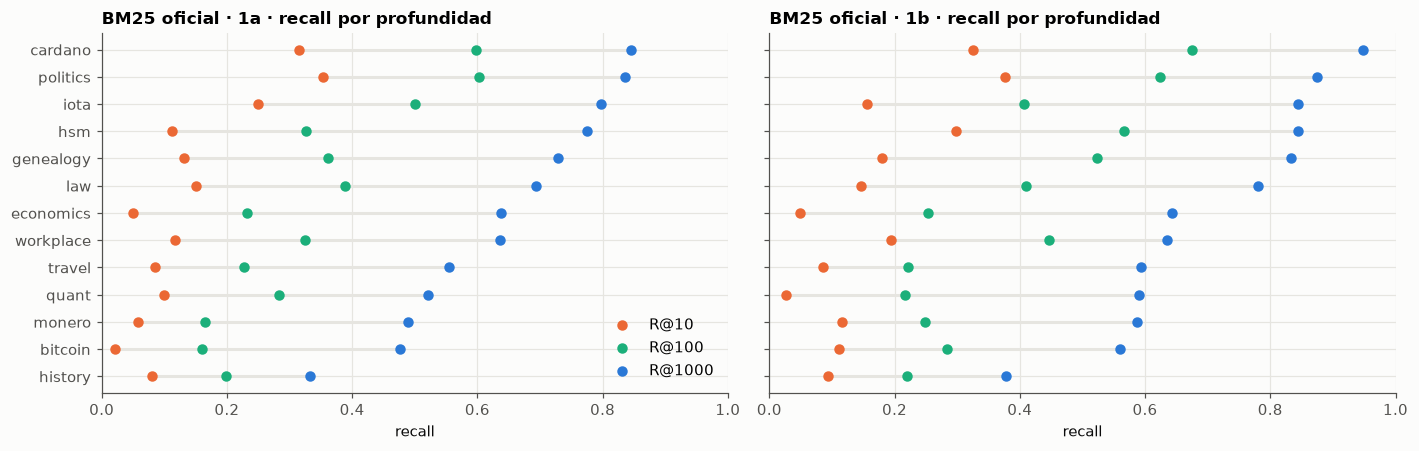

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, sub in zip(axes, ["1a", "1b"]):
    t = bm25_summary[sub].drop("MACRO").sort_values("recall_1000")
    y = np.arange(len(t))
    for col, color, lab in [("recall_10", C_NOGOLD, "R@10"), ("recall_100", C_THIRD, "R@100"), ("recall_1000", C_GOLD, "R@1000")]:
        ax.scatter(t[col], y, color=color, s=34, label=lab, zorder=3)
    for i, d in enumerate(t.index):
        ax.plot([t.loc[d, "recall_10"], t.loc[d, "recall_1000"]], [i, i], color=GRID, lw=2, zorder=2)
    ax.set_yticks(y, t.index)
    ax.set_xlim(0, 1)
    style_ax(ax, f"BM25 oficial · {sub} · recall por profundidad", "recall")
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 3. Comparación con el paper de TEMPO

Paper: Abdallah et al., *TEMPO: A Realistic Multi-Domain Benchmark for Temporal Reasoning-Intensive Retrieval* (arXiv 2601.09523v1; `papers/2601.09523v1.pdf`). Las cifras de las tablas se copian a mano (escala 0–100).

**Por qué no son directamente comparables.** Lo que nos dieron (RETECO v1.1) y lo que evaluó el paper difieren en tres cosas que se pueden comprobar en `README.md` y `split_manifest.json`:

1. **Corpus deduplicado (v1.1).** El paper usa el corpus original de 1,654,055 documentos; el release v1.1 elimina 486,896 copias idénticas (29.4 %), con reducciones del 37–50 % en `bitcoin`, `cardano`, `history` y `monero`. Cambian los candidatos, la longitud media y el idf de cada dominio.
2. **Evaluación sobre todas las consultas.** El paper evalúa las 1,730 consultas; el baseline oficial de RETECO se mide solo sobre **train** (70 %, split por consulta con semilla fija). En dominios pequeños (`iota`: 7 train + 3 dev) eso basta para mover el nDCG@10 varios puntos.
3. **Qrels fusionados.** Al deduplicar se fusionaron 92 IDs gold con texto idéntico y 57 líneas de qrels repetidas.

Además, el paper **no detalla su implementación de BM25** (analizador, `k1`, `b`, profundidad del ranking): solo dice "BM25 (Robertson et al., 2009)". No podemos confirmar que sea la misma que la del starter kit.

Para aislar el efecto del split, aquí se evalúa el baseline **también en dev** y se agrupan train + dev (= las mismas 1,730 consultas del paper). Es solo una comparación de cifras: no se toma ninguna decisión de diseño con dev.

### 3.1 Cifras del paper

In [13]:
# Cifras del paper TEMPO (arXiv 2601.09523v1), copiadas a mano de sus tablas. Escala 0-100.
#   Tabla 2: consultas (Q), documentos (D), positivos por consulta, pasos por consulta
#   Tabla 3: nDCG@10 de BM25 en 1a (todas las consultas)
#   Tabla 40: Recall@10 de BM25 en 1a
#   Tablas 19 y 20: nDCG@10 de BM25 en 1b, estrategias Step-Only y Query+Step
PAPER = pd.DataFrame({
    "Q": {"bitcoin": 100, "cardano": 51, "iota": 10, "monero": 65, "economics": 83, "law": 35, "politics": 150,
          "history": 801, "quant": 34, "travel": 100, "workplace": 36, "genealogy": 115, "hsm": 150},
    "D": {"bitcoin": 153291, "cardano": 87201, "iota": 10372, "monero": 85093, "economics": 93756, "law": 43288,
          "politics": 183394, "history": 356493, "quant": 28785, "travel": 177677, "workplace": 64659,
          "genealogy": 156228, "hsm": 213818},
    "pos_por_consulta": {"bitcoin": 3.3, "cardano": 2.5, "iota": 3.8, "monero": 2.6, "economics": 3.6, "law": 3.0,
                         "politics": 2.7, "history": 4.5, "quant": 2.4, "travel": 2.6, "workplace": 2.8,
                         "genealogy": 2.8, "hsm": 2.5},
    "pasos_por_consulta": {"bitcoin": 2.93, "cardano": 2.84, "iota": 3.20, "monero": 2.72, "economics": 3.08,
                           "law": 3.23, "politics": 3.35, "history": 3.42, "quant": 2.68, "travel": 3.11,
                           "workplace": 2.42, "genealogy": 3.78, "hsm": 3.25},
    "1a_ndcg10": {"bitcoin": 6.2, "cardano": 13.4, "iota": 9.7, "monero": 2.8, "economics": 5.8, "law": 12.7,
                  "politics": 32.7, "history": 9.2, "quant": 2.5, "travel": 4.6, "workplace": 6.2, "genealogy": 13.3,
                  "hsm": 21.2},
    "1a_recall10": {"bitcoin": 8.5, "cardano": 20.6, "iota": 11.7, "monero": 4.7, "economics": 6.2, "law": 16.5,
                    "politics": 38.3, "history": 10.4, "quant": 2.9, "travel": 7.1, "workplace": 9.3, "genealogy": 15.2,
                    "hsm": 26.9},
    "1b_paso_ndcg10": {"bitcoin": 4.1, "cardano": 9.1, "iota": 15.1, "monero": 7.4, "economics": 8.6, "law": 17.3,
                       "politics": 18.6, "history": 10.9, "quant": 6.0, "travel": 6.7, "workplace": 19.4,
                       "genealogy": 15.1, "hsm": 12.5},
    "1b_consulta+paso_ndcg10": {"bitcoin": 6.2, "cardano": 9.7, "iota": 13.8, "monero": 4.2, "economics": 5.8,
                                "law": 13.8, "politics": 28.1, "history": 9.3, "quant": 1.9, "travel": 4.5,
                                "workplace": 9.4, "genealogy": 14.1, "hsm": 20.2},
}).loc[DOMAINS]
PAPER_AVG = {"1a_ndcg10": 10.8, "1a_recall10": 13.7, "1b_paso_ndcg10": 11.6, "1b_consulta+paso_ndcg10": 10.8}
PAPER_TOTALS = {"consultas": 1730, "documentos": 1_654_055, "consultas_con_pasos": 1605, "pasos": 3976}

# Comprobación de la transcripción: el promedio de las 13 filas debe reproducir el "Avg." publicado.
chk = pd.DataFrame({"promedio_filas": PAPER[list(PAPER_AVG)].mean().round(1), "avg_publicado": pd.Series(PAPER_AVG)})
chk["coincide"] = (chk["promedio_filas"] - chk["avg_publicado"]).abs() <= 0.1
display(chk)
assert PAPER["Q"].sum() == PAPER_TOTALS["consultas"] and PAPER["D"].sum() == PAPER_TOTALS["documentos"]

,promedio_filas,avg_publicado,coincide
1a_ndcg10,10.8,10.8,True
1a_recall10,13.7,13.7,True
1b_paso_ndcg10,11.6,11.6,True
1b_consulta+paso_ndcg10,10.8,10.8,True


### 3.2 ¿Son los mismos datos? Consultas, documentos, gold y pasos

- **Documentos:** `D_paper` frente a `D_v1.1 + eliminados`. Si el corpus del paper es el v1.0 original, deben coincidir exactamente.
- **Consultas:** train + dev frente a `Q`.
- **Gold por consulta** y **pasos por consulta** (solo consultas con al menos un paso) frente a las columnas del paper.

In [14]:
inv = []
for dom in DOMAINS:
    ex = load_examples(dom, "train") + load_examples(dom, "dev")
    st = load_steps(dom, "train") + load_steps(dom, "dev")
    n_docs = len(pd.read_parquet(STATS_DIR / f"{dom}.parquet", columns=["id"]))
    n_removed = len(load_duplicate_map(dom))
    steps_q = [len(r["steps"]) for r in st if r["steps"]]
    inv.append({
        "dominio": dom,
        "Q_paper": PAPER.loc[dom, "Q"], "Q_train+dev": len(ex),
        "D_paper": PAPER.loc[dom, "D"], "D_v1.1": n_docs, "D_eliminados": n_removed, "D_v1.1+elim": n_docs + n_removed,
        "%eliminado": round(100 * n_removed / (n_docs + n_removed), 1),
        "gold/q_paper": PAPER.loc[dom, "pos_por_consulta"], "gold/q_nuestro": round(np.mean([len(r["gold_ids"]) for r in ex]), 2),
        "pasos/q_paper": PAPER.loc[dom, "pasos_por_consulta"], "pasos/q_nuestro": round(np.mean(steps_q), 2),
        "consultas_con_pasos": len(steps_q), "pasos": sum(steps_q),
    })
inv = pd.DataFrame(inv).set_index("dominio")
inv["D_coincide"] = inv["D_paper"] == inv["D_v1.1+elim"]
display(inv.drop(columns=["consultas_con_pasos", "pasos"]))
print(f"Consultas: nuestro {inv['Q_train+dev'].sum()} vs paper {PAPER_TOTALS['consultas']}")
print(f"Documentos v1.1: {inv['D_v1.1'].sum():,}  (+ {inv['D_eliminados'].sum():,} eliminados = {inv['D_v1.1+elim'].sum():,}; paper: {PAPER_TOTALS['documentos']:,})")
print(f"Consultas con pasos: {inv['consultas_con_pasos'].sum()} (paper {PAPER_TOTALS['consultas_con_pasos']}); pasos: {inv['pasos'].sum()} (paper {PAPER_TOTALS['pasos']})")
print(f"Dominios donde D_paper == D_v1.1 + eliminados: {int(inv['D_coincide'].sum())} de {len(inv)}")

,Q_paper,Q_train+dev,D_paper,D_v1.1,D_eliminados,D_v1.1+elim,%eliminado,gold/q_paper,gold/q_nuestro,pasos/q_paper,pasos/q_nuestro,D_coincide
dominio,,,,,,,,,,,,
bitcoin,100,100,153291,76706,76585,153291,50.0,3.3,3.24,2.93,2.14,True
cardano,51,51,87201,47509,39692,87201,45.5,2.5,2.41,2.84,2.09,True
economics,83,83,93756,74692,19064,93756,20.3,3.6,3.58,3.08,2.38,True
genealogy,115,115,156228,136101,20127,156228,12.9,2.8,2.83,3.78,2.20,True
history,801,801,356493,200252,156241,356493,43.8,4.5,4.43,3.42,2.67,True
hsm,150,150,213818,169552,44266,213818,20.7,2.5,2.45,3.25,2.53,True
iota,10,10,10372,9680,692,10372,6.7,3.8,3.80,3.20,2.40,True
law,35,35,43288,36110,7178,43288,16.6,3.0,3.00,3.23,2.24,True
monero,65,65,85093,53955,31138,85093,36.6,2.6,2.58,2.72,2.06,True


Consultas: nuestro 1730 vs paper 1730
Documentos v1.1: 1,167,159  (+ 486,896 eliminados = 1,654,055; paper: 1,654,055)
Consultas con pasos: 1605 (paper 1605); pasos: 3976 (paper 3976)
Dominios donde D_paper == D_v1.1 + eliminados: 13 de 13


In [15]:
# El "Steps" del paper (pasos por consulta) parece contar TODAS las acciones del retrieval_plan, también las
# que no tienen gold y por eso no son pasos de 1b. Se comprueba con el guidance.
plan = {}
for dom in DOMAINS:
    n = [len(g["query_guidance"]["retrieval_plan"]) for s in ("train", "dev") for g in load_guidance(dom, s)
         if g["query_guidance"]["retrieval_plan"]]
    plan[dom] = np.mean(n)
chk_plan = pd.DataFrame({"pasos/q_paper": PAPER["pasos_por_consulta"], "acciones_plan/q": pd.Series(plan).round(2),
                         "pasos_con_gold/q": inv["pasos/q_nuestro"]})
display(chk_plan)
print(f"|paper - acciones del plan| medio: {(chk_plan['pasos/q_paper'] - chk_plan['acciones_plan/q']).abs().mean():.2f}  "
      f"vs |paper - pasos con gold|: {(chk_plan['pasos/q_paper'] - chk_plan['pasos_con_gold/q']).abs().mean():.2f}")

,pasos/q_paper,acciones_plan/q,pasos_con_gold/q
bitcoin,2.93,3.08,2.14
cardano,2.84,2.96,2.09
economics,3.08,3.24,2.38
genealogy,3.78,3.78,2.20
history,3.42,3.43,2.67
hsm,3.25,3.32,2.53
iota,3.20,3.20,2.40
law,3.23,3.23,2.24
monero,2.72,3.00,2.06
politics,3.35,3.35,2.66


|paper - acciones del plan| medio: 0.13  vs |paper - pasos con gold|: 0.83


### 3.3 Baseline en train, dev y train + dev

Se ejecutan en **dev** las variantes `1a_oficial`, `1b_oficial` (consulta + paso) y `1b_paso` (solo el paso, equivalente a *Step-Only* del paper); en train ya existen. Después se agrupan train + dev por dominio para tener las mismas 1,730 consultas que el paper.

Detalles de la comparación:
- 1a ↔ Tabla 3 (nDCG@10) y Tabla 40 (Recall@10). 1b `oficial` ↔ *Query+Step* (Tabla 20) y 1b `paso` ↔ *Step-Only* (Tabla 19).
- El paper dice que en 1b promedia "across steps"; no aclara si por paso o por consulta. Aquí se reporta el promedio **por paso** (como el scorer oficial) y, aparte, el promedio por consulta.
- Macro = media de los 13 dominios, como el "Avg." del paper.

In [16]:
SPLITS_CMP = ("train", "dev")
CMP_VARIANTS = ["1a_oficial", "1b_oficial", "1b_paso"]
CMP_MEASURES = ("ndcg_cut.10", "recall.10")

t0 = time.time()
run_bm25_variants("dev", CMP_VARIANTS)  # train ya está en caché
print(f"Runs de dev listos en {time.time() - t0:.0f} s")


def eval_split(variant: str, split: str) -> pd.DataFrame:
    """nDCG@10 y Recall@10 por consulta/paso de una variante en todos los dominios de un split."""
    sub = TOPIC_VARIANTS[variant][0]
    frames = [evaluate_run(load_run(variant, d, split), load_qrels(d, split, sub), CMP_MEASURES).assign(domain=d, split=split)
              for d in DOMAINS]
    return pd.concat(frames)


CMP = {v: pd.concat([eval_split(v, s) for s in SPLITS_CMP]) for v in CMP_VARIANTS}
for v, df in CMP.items():
    print(f"{v}: {df.groupby('split').size().to_dict()} consultas/pasos evaluados")


def dom_table(variant: str, metric: str, paper_col: str) -> pd.DataFrame:
    """Tabla por dominio (escala 0-100): paper, train, dev, train+dev y diferencia (train+dev) - paper."""
    df = CMP[variant]
    t = pd.DataFrame({"paper": PAPER[paper_col],
                      "train": 100 * df[df["split"] == "train"].groupby("domain")[metric].mean(),
                      "dev": 100 * df[df["split"] == "dev"].groupby("domain")[metric].mean(),
                      "train+dev": 100 * df.groupby("domain")[metric].mean()})
    t["Δ (t+d − paper)"] = t["train+dev"] - t["paper"]
    t.loc["MACRO"] = t.mean()
    return t


TABLES = {
    "1a · nDCG@10": dom_table("1a_oficial", "ndcg_cut_10", "1a_ndcg10"),
    "1a · Recall@10": dom_table("1a_oficial", "recall_10", "1a_recall10"),
    "1b consulta+paso · nDCG@10": dom_table("1b_oficial", "ndcg_cut_10", "1b_consulta+paso_ndcg10"),
    "1b solo paso · nDCG@10": dom_table("1b_paso", "ndcg_cut_10", "1b_paso_ndcg10"),
}
for name, t in TABLES.items():
    display(Markdown(f"**BM25 · {name}** (escala 0–100)"))
    display(t.round(1))

Runs de dev listos en 0 s


1a_oficial: {'dev': 519, 'train': 1211} consultas/pasos evaluados
1b_oficial: {'dev': 1214, 'train': 2762} consultas/pasos evaluados
1b_paso: {'dev': 1214, 'train': 2762} consultas/pasos evaluados


**BM25 · 1a · nDCG@10** (escala 0–100)

,paper,train,dev,train+dev,Δ (t+d − paper)
bitcoin,6.2,8.6,3.7,7.1,0.9
cardano,13.4,18.5,10.3,16.1,2.7
economics,5.8,3.8,4.7,4.1,-1.7
genealogy,13.3,12.4,19.5,14.6,1.3
history,9.2,6.5,8.7,7.2,-2.0
hsm,21.2,17.4,24.9,19.6,-1.6
iota,9.7,15.6,33.1,20.9,11.2
law,12.7,9.5,5.7,8.3,-4.4
monero,2.8,3.8,3.2,3.6,0.8
politics,32.7,28.1,26.2,27.5,-5.2


**BM25 · 1a · Recall@10** (escala 0–100)

,paper,train,dev,train+dev,Δ (t+d − paper)
bitcoin,8.5,9.9,6.8,9.0,0.4
cardano,20.6,31.5,14.4,26.5,5.9
economics,6.2,4.9,5.1,5.0,-1.2
genealogy,15.2,15.1,22.3,17.3,2.1
history,10.4,8.0,10.5,8.7,-1.7
hsm,26.9,25.0,32.4,27.2,0.3
iota,11.7,13.1,38.9,20.8,9.1
law,16.5,11.2,9.1,10.6,-5.9
monero,4.7,5.8,7.9,6.4,1.7
politics,38.3,35.4,33.9,34.9,-3.4


**BM25 · 1b consulta+paso · nDCG@10** (escala 0–100)

,paper,train,dev,train+dev,Δ (t+d − paper)
bitcoin,6.2,8.9,3.0,7.1,0.9
cardano,9.7,16.5,6.3,12.8,3.1
economics,5.8,3.0,4.6,3.5,-2.3
genealogy,14.1,11.8,21.8,14.8,0.7
history,9.3,6.1,10.1,7.4,-1.9
hsm,20.2,17.3,21.4,18.5,-1.7
iota,13.8,14.0,42.0,23.3,9.5
law,13.8,8.5,5.5,7.6,-6.2
monero,4.2,6.2,1.1,4.8,0.6
politics,28.1,24.0,23.7,23.9,-4.2


**BM25 · 1b solo paso · nDCG@10** (escala 0–100)

,paper,train,dev,train+dev,Δ (t+d − paper)
bitcoin,4.1,5.5,6.6,5.9,1.8
cardano,9.1,8.7,13.9,10.6,1.5
economics,8.6,8.3,6.2,7.7,-0.9
genealogy,15.1,15.6,13.9,15.1,0.0
history,10.9,8.8,9.8,9.1,-1.8
hsm,12.5,10.8,15.9,12.3,-0.2
iota,15.1,14.9,28.3,19.3,4.2
law,17.3,12.7,14.9,13.4,-3.9
monero,7.4,10.3,2.2,8.1,0.7
politics,18.6,17.6,16.1,17.1,-1.5


### 3.4 ¿Cuánto se parece a las cifras del paper y de dónde vienen las diferencias?

Train + dev son **las mismas 1,730 consultas** del paper, así que el split ya no explica la diferencia que quede. Lo que se mide aquí:

- **Diferencia con el paper** por dominio (media de |Δ|) y correlación de Spearman entre ambas columnas (¿mismo orden de dificultad?).
- **|train − dev|**: cuánto se mueve el baseline solo por qué consultas se miran. Sirve de escala para saber si una diferencia por dominio es grande o pequeña.
- **Spearman(Δ, %eliminado)**: si la deduplicación explicara las diferencias, los dominios con más documentos eliminados (`bitcoin` 50 %, `cardano` 46 %, `history` 44 %) deberían desviarse más.

Para la variante 1b, además, se compara el promedio por paso con el promedio por consulta.

In [17]:
rows = []
for name, t in TABLES.items():
    d = t.drop(index="MACRO")
    lo, hi = d[["train", "dev"]].min(axis=1), d[["train", "dev"]].max(axis=1)
    rows.append({
        "métrica": name,
        "macro paper": t.loc["MACRO", "paper"], "macro train": t.loc["MACRO", "train"],
        "macro dev": t.loc["MACRO", "dev"], "macro train+dev": t.loc["MACRO", "train+dev"],
        "|Δ| medio por dominio (t+d vs paper)": d["Δ (t+d − paper)"].abs().mean(),
        "|train − dev| medio": (d["train"] - d["dev"]).abs().mean(),
        "paper dentro del rango [train, dev]": f"{int(((d['paper'] >= lo) & (d['paper'] <= hi)).sum())} / {len(d)}",
        "Spearman(Δ, %eliminado)": d["Δ (t+d − paper)"].corr(inv["%eliminado"], method="spearman"),
        "Spearman(paper, t+d)": d["paper"].corr(d["train+dev"], method="spearman"),
    })
noise = pd.DataFrame(rows).set_index("métrica")
display(noise.round(2))

# 1b: promedio por paso (scorer oficial) frente a promedio por consulta (primero los pasos de cada consulta)
one_b = CMP["1b_oficial"].copy()
one_b["qid"] = one_b.index.str.replace(r"_step\d+$", "", regex=True)
per_q = one_b.groupby(["domain", "qid"])["ndcg_cut_10"].mean().groupby("domain").mean() * 100
per_step = one_b.groupby("domain")["ndcg_cut_10"].mean() * 100
agg = pd.DataFrame({"paper (Query+Step)": PAPER["1b_consulta+paso_ndcg10"], "por paso": per_step, "por consulta": per_q})
agg.loc["MACRO"] = agg.mean()
display(Markdown("**1b consulta+paso · nDCG@10 según cómo se promedia** (train + dev, escala 0–100)"))
display(agg.round(1))

,macro paper,macro train,macro dev,macro train+dev,|Δ| medio por dominio (t+d vs paper),|train − dev| medio,"paper dentro del rango [train, dev]","Spearman(Δ, %eliminado)","Spearman(paper, t+d)"
métrica,,,,,,,,,
1a · nDCG@10,10.79,10.75,11.47,10.97,2.47,4.68,7 / 13,-0.08,0.94
1a · Recall@10,13.72,14.03,15.36,14.43,2.59,6.25,7 / 13,-0.20,0.94
1b consulta+paso · nDCG@10,10.85,10.24,11.77,10.66,2.53,6.65,9 / 13,-0.01,0.94
1b solo paso · nDCG@10,11.60,11.04,12.88,11.64,1.32,4.25,8 / 13,0.08,0.96


**1b consulta+paso · nDCG@10 según cómo se promedia** (train + dev, escala 0–100)

,paper (Query+Step),por paso,por consulta
bitcoin,6.2,7.1,8.6
cardano,9.7,12.8,13.6
economics,5.8,3.5,2.7
genealogy,14.1,14.8,13.3
history,9.3,7.4,7.7
hsm,20.2,18.5,17.8
iota,13.8,23.3,24.6
law,13.8,7.6,7.7
monero,4.2,4.8,4.7
politics,28.1,23.9,23.7


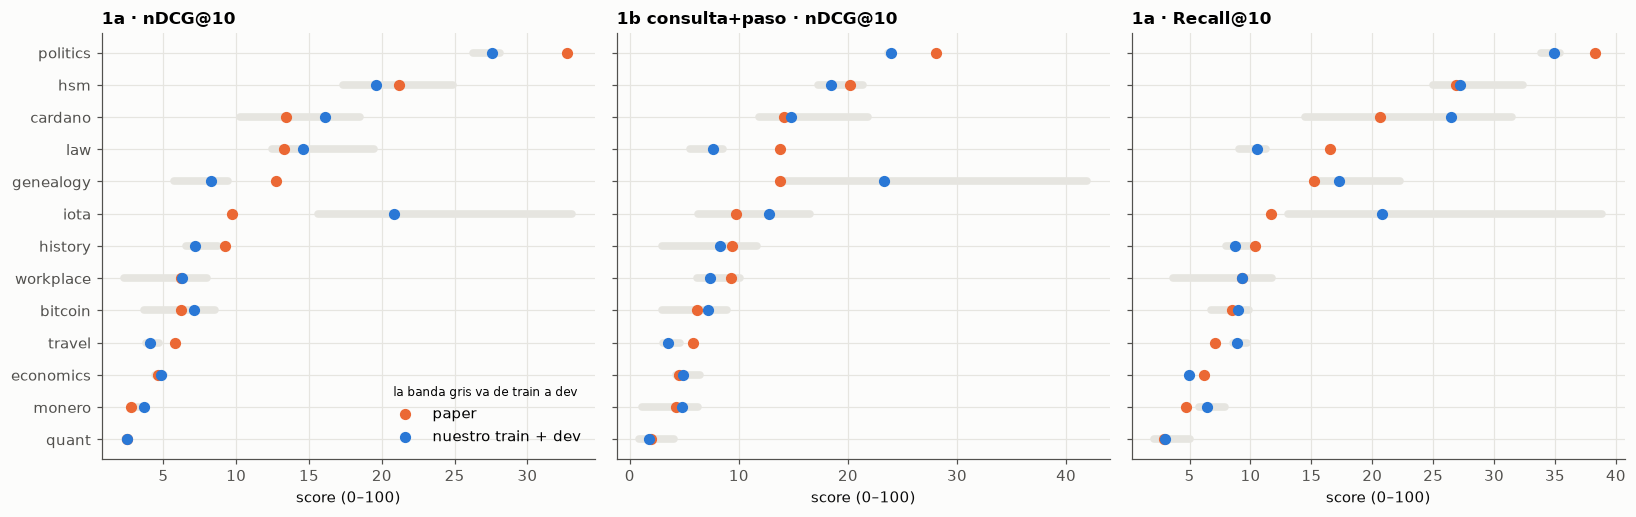

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, name in zip(axes, ["1a · nDCG@10", "1b consulta+paso · nDCG@10", "1a · Recall@10"]):
    t = TABLES[name].drop(index="MACRO").sort_values("paper")
    y = np.arange(len(t))
    for i, d in enumerate(t.index):  # tramo train–dev: cuánto se mueve el baseline solo por el split
        ax.plot([t.loc[d, "train"], t.loc[d, "dev"]], [i, i], color=GRID, lw=5, zorder=1, solid_capstyle="round")
    ax.scatter(t["paper"], y, color=C_NOGOLD, s=40, label="paper", zorder=3)
    ax.scatter(t["train+dev"], y, color=C_GOLD, s=40, label="nuestro train + dev", zorder=3)
    ax.set_yticks(y, t.index)
    style_ax(ax, name, "score (0–100)")
axes[0].legend(loc="lower right", title="la banda gris va de train a dev", title_fontsize=8)
plt.tight_layout(); plt.show()

### 3.5 Conclusiones de la comparación

**1. Los datos son los mismos; lo único que cambió de contenido es la deduplicación.**
- Consultas (1,730), consultas con pasos (1,605) y pasos (3,976) coinciden exactamente con el paper.
- El tamaño del corpus del paper coincide exactamente, en los 13 dominios, con `documentos v1.1 + eliminados`. O sea, el paper usó el corpus v1.0 y RETECO v1.1 solo le quitó 486,896 copias idénticas (29.4 %).
- Los gold por consulta son casi iguales (p. ej. `bitcoin` 3.24 frente a 3.3), con diferencias pequeñas por la fusión de 92 IDs gold.
- Los "pasos por consulta" del paper (p. ej. `bitcoin` 2.93) **no** son los pasos de 1b (2.14): cuentan todas las acciones del `retrieval_plan`, incluidas las que no tienen gold. El promedio de acciones del plan coincide con el paper (exacto en `genealogy`, `iota`, `law` y `politics`).

**2. En promedio, el baseline reproduce el del paper.** Macro nDCG@10 1a: 11.0 (train + dev) frente a 10.8; Recall@10: 14.4 frente a 13.7; 1b consulta+paso: 10.7 frente a 10.8; 1b solo paso: 11.6 frente a 11.6. Esto sugiere que la implementación de BM25 del paper es equivalente a la del starter kit, aunque el paper no la detalla.

**3. Por dominio hay diferencias de ~2.5 puntos de media, concentradas en pocos dominios.** `iota` (+11.2; solo 10 consultas, una consulta mueve el dominio ~10 puntos), `politics` (−5.2), `law` (−4.4) y `cardano` (+2.7). El orden de dificultad entre dominios es prácticamente el mismo (Spearman 0.94–0.96).

**4. La deduplicación no explica las diferencias de forma simple.** La correlación entre la diferencia y el % de documentos eliminados es ≈ 0 (−0.2 a 0.1). Sin el corpus v1.0 no se puede aislar el efecto de la deduplicación (cambia idf, longitud media y los empates con copias) del de pequeñas diferencias de implementación (analizador, `k1`/`b`, desempates), que el paper no especifica.

**5. Qué implica para nosotros.**
- Las cifras de `BASELINE_RESULTS.md` (solo train) y las del paper (train + dev) **no son comparables dominio a dominio**: |train − dev| medio es de ~4.7 puntos en 1a, más que la distancia a las cifras del paper (~2.5). Para comparar con el paper hay que usar train + dev, y solo en macro.
- Entre dominios pequeños (`iota`, `quant`, `law`, `workplace`) no hay que sacar conclusiones con una diferencia de pocos puntos.
- El paper reporta, además de nDCG@10, métricas temporales (TP, TR, TC, nDCG|FC) que requieren un juez LLM; no se pueden reproducir con `pytrec_eval`.
- Esta sección usa dev solo para esta comparación; no se tomaron decisiones de diseño con esas cifras.

## 4. Diagnóstico de errores y variantes (train)

### 4.1 Posición del mejor gold en el ranking

En qué tramo del ranking BM25 oficial (1a) aparece el primer documento gold. Resume cuánto se pierde en la primera etapa: si el gold ni siquiera entra en el top-1000, ningún reranker puede recuperarlo.

In [19]:
def best_gold_rank(run: dict, qrels: dict) -> pd.Series:
    """Posición (1-indexada) del primer documento gold en cada ranking.

    Args:
        run: ``{qid: {doc_id: score}}``.
        qrels: ``{qid: {doc_id: rel}}``.

    Returns:
        Serie por qid; ``np.inf`` si ningún gold aparece en el ranking (top-k).
    """
    out = {}
    for qid, docs in run.items():
        ranked = sorted(docs, key=docs.get, reverse=True)
        gold = qrels.get(qid, {})
        out[qid] = next((i + 1 for i, d in enumerate(ranked) if d in gold), np.inf)
    return pd.Series(out)


ranks = pd.concat([best_gold_rank(load_run("1a_oficial", d), load_qrels(d)).rename("rank").to_frame().assign(domain=d)
                   for d in DOMAINS])
buckets = pd.cut(ranks["rank"].replace(np.inf, 10_000), [0, 1, 10, 100, 1000, np.inf],
                 labels=["1", "2–10", "11–100", "101–1000", ">1000"])
display((100 * pd.crosstab(ranks["domain"], buckets, normalize="index")).round(1))

rank,1,2–10,11–100,101–1000,>1000
domain,,,,,
bitcoin,10.0,5.7,30.0,24.3,30.0
cardano,5.6,41.7,33.3,13.9,5.6
economics,3.4,8.6,31.0,41.4,15.5
genealogy,8.8,20.0,28.7,25.0,17.5
history,5.7,10.3,20.1,19.3,44.6
hsm,11.4,32.4,27.6,21.9,6.7
iota,28.6,14.3,42.9,14.3,0.0
law,8.3,16.7,25.0,37.5,12.5
monero,2.2,13.0,19.6,37.0,28.3


### 4.2 ¿Basta la instrucción sola? BM25 con distintas formulaciones

Comparación con BM25 (misma implementación que el oficial):

- **paso:** solo `step_instruction`;
- **consulta:** solo la consulta cruda (igual para todos los pasos de una consulta);
- **oficial:** `query + "\n\nStep: " + step_instruction` (starter kit);
- **limpia+paso:** consulta sin HTML + instrucción.

In [20]:
variants_1b = ["1b_paso", "1b_consulta", "1b_oficial", "1b_limpia+paso"]
tab = pd.DataFrame({v.removeprefix("1b_"): macro_by_domain(EVAL[v])[0] for v in variants_1b})
tab.loc["MACRO"] = tab.mean()
tab_r = pd.DataFrame({v.removeprefix("1b_"): macro_by_domain(EVAL[v], "recall_100")[1] for v in variants_1b}, index=["MACRO R@100"])
display(Markdown("**nDCG@10 por dominio (1b, train)**"))
tab_all = pd.concat([tab, tab_r]).round(4)
tab_all["mejor"] = tab_all.idxmax(axis=1)
display(tab_all)

**nDCG@10 por dominio (1b, train)**

,paso,consulta,oficial,limpia+paso,mejor
bitcoin,0.0555,0.0877,0.0888,0.0916,limpia+paso
cardano,0.0871,0.1522,0.1655,0.1886,limpia+paso
economics,0.0829,0.0357,0.0300,0.0422,paso
genealogy,0.1564,0.1139,0.1181,0.1280,paso
history,0.0883,0.0625,0.0614,0.0791,paso
hsm,0.1084,0.1581,0.1729,0.1847,limpia+paso
iota,0.1486,0.1321,0.1403,0.1250,paso
law,0.1273,0.0917,0.0854,0.0897,paso
monero,0.1031,0.0734,0.0622,0.0641,paso
politics,0.1755,0.2433,0.2403,0.2608,limpia+paso


### 4.3 Rendimiento del baseline por clase temporal

nDCG@10 del BM25 oficial en train, segmentado por clase primaria e intención. Las clases con menos de 15 consultas se marcan como poco fiables.

In [21]:
seg = bm25_1a.reset_index().rename(columns={"index": "qid"}).merge(guid, on=["qid", "domain"])
seg = seg.merge(queries[["id", "alguna"]].rename(columns={"id": "qid", "alguna": "expr_temporal_explicita"}), on="qid")


def segment_table(df: pd.DataFrame, col: str, min_n: int = 15) -> pd.DataFrame:
    """nDCG@10 y Recall@100 medios por valor de una columna categórica.

    Args:
        df: DataFrame por consulta con ``ndcg_cut_10`` y ``recall_100``.
        col: columna de segmentación.
        min_n: tamaño mínimo para considerar fiable un segmento.

    Returns:
        Tabla ordenada de peor a mejor nDCG@10, con el número de consultas.
    """
    t = df.groupby(col).agg(n=("qid", "size"), nDCG10=("ndcg_cut_10", "mean"), R100=("recall_100", "mean"),
                            pct_nDCG_0=("ndcg_cut_10", lambda s: 100 * (s == 0).mean()))
    t["fiable"] = t["n"] >= min_n
    return t.round(3).sort_values("nDCG10")


for col in ["clase_primaria", "temporal_intent", "granularidad_top", "expr_temporal_explicita"]:
    display(Markdown(f"**BM25 1a por `{col}`**"))
    display(segment_table(seg, col))

**BM25 1a por `clase_primaria`**

,n,nDCG10,R100,pct_nDCG_0,fiable
clase_primaria,,,,,
historical_misinterpretation_or_reenactment,1,0.000,0.000,100.000,False
none,1,0.000,0.000,100.000,False
(vacío),36,0.051,0.259,88.889,True
materials_artifacts_and_provenance,68,0.063,0.231,82.353,True
time_period_contextualization,256,0.067,0.248,82.422,True
origins_evolution_comparative_analysis,171,0.072,0.250,77.193,True
trends_changes_and_cross_period,117,0.074,0.241,82.051,True
sources_methods_and_documentation,15,0.104,0.385,66.667,True
causation_analysis,15,0.106,0.233,80.000,True


**BM25 1a por `temporal_intent`**

,n,nDCG10,R100,pct_nDCG_0,fiable
temporal_intent,,,,,
after,5,0.000,0.240,100.000,False
since,1,0.000,0.500,100.000,False
during,1,0.000,0.000,100.000,False
why,1,0.000,0.500,100.000,False
causation_analysis,1,0.000,0.000,100.000,False
event_analysis_and_localization,2,0.046,0.143,50.000,False
period_definition,244,0.060,0.213,84.016,True
trends_changes_and_cross_period,6,0.064,0.250,83.333,False
duration,101,0.067,0.238,81.188,True


**BM25 1a por `granularidad_top`**

,n,nDCG10,R100,pct_nDCG_0,fiable
granularidad_top,,,,,
era,25,0.016,0.179,92.000,True
century,132,0.041,0.182,83.333,True
duration,20,0.046,0.362,75.000,True
(vacío),40,0.053,0.270,85.000,True
month,51,0.063,0.238,86.275,True
period,102,0.077,0.251,77.451,True
decade,138,0.087,0.324,78.261,True
otras,176,0.098,0.284,78.977,True
date,117,0.110,0.355,79.487,True


**BM25 1a por `expr_temporal_explicita`**

,n,nDCG10,R100,pct_nDCG_0,fiable
expr_temporal_explicita,,,,,
False,240,0.086,0.335,75.833,True
True,971,0.103,0.287,77.137,True


In [22]:
# Mismo análisis para 1b, heredando la clase de la consulta madre.
seg_b = EVAL["1b_oficial"].reset_index().rename(columns={"index": "step_id"})
seg_b["qid"] = seg_b["step_id"].str.replace(r"_step\d+$", "", regex=True)
seg_b = seg_b.merge(guid[["qid", "clase_primaria"]], on="qid")
display(Markdown("**BM25 1b por `clase_primaria`**"))
display(segment_table(seg_b, "clase_primaria"))

**BM25 1b por `clase_primaria`**

,n,nDCG10,R100,pct_nDCG_0,fiable
clase_primaria,,,,,
historical_misinterpretation_or_reenactment,3,0.000,0.000,100.000,False
sources_methods_and_documentation,26,0.058,0.426,80.769,True
(vacío),31,0.062,0.323,90.323,True
origins_evolution_comparative_analysis,455,0.065,0.285,85.495,True
trends_changes_and_cross_period,264,0.067,0.251,85.985,True
time_period_contextualization,604,0.068,0.273,86.921,True
materials_artifacts_and_provenance,145,0.081,0.321,84.138,True
causation_analysis,42,0.123,0.226,80.952,True
event_analysis_and_localization,974,0.123,0.395,77.515,True


### 4.4 Baseline denso rápido (BGE-small) en dominios pequeños

`BAAI/bge-small-en-v1.5` con `sentence-transformers` en `iota`, `quant` y `law`, con búsqueda exacta por producto interno sobre vectores normalizados (= coseno). Decisiones:

- la búsqueda exacta se hace con un producto matricial de numpy, que equivale a `faiss.IndexFlatIP`. Con FAISS el kernel se caía en este entorno (conflicto entre los runtimes OpenMP de faiss/torch/sklearn y la JVM de Pyserini en el mismo proceso), y con ≤36k documentos numpy es igual de rápido. Para `history`/`hsm` sí convendrá FAISS (con índices aproximados), pero en un proceso sin la JVM;

- documentos truncados a 512 tokens (sin chunking; ver 2.1 del EDA para cuánto se pierde);
- consultas limpias (sin HTML) con el prefijo de búsqueda recomendado por BGE;
- en 1b el paso va **delante** de la consulta, porque las consultas largas se truncan y el paso se perdería al final;
- también se prueba una fusión híbrida simple BM25 + denso con *Reciprocal Rank Fusion* (RRF, k=60).

In [23]:
import torch
from sentence_transformers import SentenceTransformer

DENSE_DOMAINS = ["iota", "quant", "law"]
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
EMB_DIR = CACHE_DIR / "dense"
EMB_DIR.mkdir(exist_ok=True)

dense_model = SentenceTransformer(DENSE_MODEL, device=DEVICE)
dense_model.max_seq_length = 512
print(f"Modelo denso en {DEVICE}")


def encode_corpus(domain: str) -> tuple[list[str], np.ndarray]:
    """Codifica (o lee de caché) todos los documentos de un dominio con el modelo denso.

    Args:
        domain: dominio a codificar.

    Returns:
        ``(doc_ids, embeddings)`` con embeddings ``float32`` normalizados (norma 1).
    """
    path = EMB_DIR / f"{domain}.npz"
    if path.exists():
        z = np.load(path, allow_pickle=True)
        return list(z["ids"]), z["emb"]
    docs = list(iter_documents(domain))
    # Ordenar por longitud agrupa textos parecidos en cada batch y reduce el padding (mucho más rápido).
    order = np.argsort([len(d["content"]) for d in docs])
    emb = dense_model.encode([docs[i]["content"] for i in order], batch_size=64, normalize_embeddings=True,
                             show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    out = np.empty_like(emb)
    out[order] = emb
    ids = [d["id"] for d in docs]
    np.savez(path, ids=np.array(ids), emb=out)
    return ids, out


def dense_search(emb: np.ndarray, doc_ids: list[str], queries: dict[str, str], k: int = 1000) -> dict:
    """Recupera los ``k`` documentos más similares a cada consulta (búsqueda exacta).

    Equivale a ``faiss.IndexFlatIP``: producto interno entre la consulta y todos los
    documentos, y selección de los ``k`` mayores.

    Args:
        emb: matriz ``(n_docs, dim)`` de embeddings normalizados del corpus.
        doc_ids: IDs en el mismo orden que ``emb``.
        queries: ``{qid: texto}`` (sin prefijo; se añade aquí).
        k: profundidad del ranking.

    Returns:
        Run ``{qid: {doc_id: score}}``.
    """
    qids = list(queries)
    qemb = dense_model.encode([BGE_QUERY_PREFIX + queries[q] for q in qids], batch_size=32,
                              normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    sims = qemb @ emb.T                              # (n_consultas, n_docs)
    k = min(k, emb.shape[0])
    top = np.argpartition(-sims, k - 1, axis=1)[:, :k]
    run = {}
    for i, q in enumerate(qids):
        order = top[i][np.argsort(-sims[i, top[i]])]
        run[q] = {doc_ids[j]: float(sims[i, j]) for j in order}
    return run


def rrf_fuse(runs: list[dict], k: int = 60, depth: int = 1000) -> dict:
    """Fusiona varios runs con Reciprocal Rank Fusion: ``score(d) = Σ 1 / (k + rank(d))``.

    Args:
        runs: lista de runs ``{qid: {doc_id: score}}``.
        k: constante de suavizado de RRF (60 es el valor habitual).
        depth: cuántos documentos conservar por consulta.

    Returns:
        Run fusionado.
    """
    fused = {}
    for qid in runs[0]:
        acc = defaultdict(float)
        for run in runs:
            ranked = sorted(run.get(qid, {}).items(), key=lambda x: -x[1])
            for r, (d, _) in enumerate(ranked, start=1):
                acc[d] += 1.0 / (k + r)
        fused[qid] = dict(sorted(acc.items(), key=lambda x: -x[1])[:depth])
    return fused

W1104 17:12:38.014000 27125 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modelo denso en mps


In [24]:
dense_rows, dense_eval = [], {}
for dom in DENSE_DOMAINS:
    t0 = time.time()
    ids, emb = encode_corpus(dom)

    q1a = {r["id"]: clean_query(r["query"]) for r in load_examples(dom)}
    q1b = {s["step_id"]: f"{s['step_instruction']} {clean_query(r['query'])}" for r in load_steps(dom) for s in r["steps"]}
    runs = {
        ("1a", "denso"): dense_search(emb, ids, q1a),
        ("1b", "denso"): dense_search(emb, ids, q1b),
        ("1a", "BM25"): load_run("1a_oficial", dom),
        ("1b", "BM25"): load_run("1b_oficial", dom),
    }
    runs[("1a", "RRF")] = rrf_fuse([runs[("1a", "BM25")], runs[("1a", "denso")]])
    runs[("1b", "RRF")] = rrf_fuse([runs[("1b", "BM25")], runs[("1b", "denso")]])
    for (sub, name), run in runs.items():
        ev = evaluate_run(run, load_qrels(dom, SPLIT, sub))
        dense_eval[(dom, sub, name)] = ev
        dense_rows.append({"dominio": dom, "sub": sub, "modelo": name, **ev.mean().round(4).to_dict()})
    print(f"{dom}: {len(ids):,} docs, {time.time() - t0:.0f} s")
    del emb

dense_df = pd.DataFrame(dense_rows)
display(dense_df.pivot_table(index=["sub", "dominio"], columns="modelo",
                             values=["ndcg_cut_10", "recall_100", "recall_1000"]).round(3))

iota: 9,680 docs, 1 s


quant: 25,040 docs, 1 s


law: 36,110 docs, 1 s


ndcg_cut_10               recall_100               recall_1000              
modelo             BM25    RRF  denso       BM25    RRF  denso        BM25    RRF  denso
sub dominio                                                                             
1a  iota          0.156  0.340  0.268      0.362  0.438  0.490       0.729  0.810  0.881
    law           0.095  0.205  0.261      0.327  0.748  0.794       0.774  0.986  0.986
    quant         0.026  0.103  0.151      0.160  0.445  0.519       0.477  0.759  0.794
1b  iota          0.140  0.310  0.258      0.406  0.656  0.656       0.844  0.844  0.844
    law           0.085  0.228  0.275      0.410  0.783  0.868       0.780  0.962  0.981
    quant         0.008  0.147  0.206      0.216  0.532  0.716       0.590  0.878  0.919

### 4.5 Varianza por dominio

Intervalo de confianza bootstrap al 95 % del nDCG@10 (BM25 1a), remuestreando consultas dentro de cada dominio. En dominios con pocas consultas el intervalo es muy ancho: una diferencia de 0.05 entre sistemas puede ser solo ruido.

,n,nDCG10,std,IC95_inf,IC95_sup,ancho_IC
dominio,,,,,,
iota,7,0.156,0.207,0.034,0.301,0.268
law,24,0.095,0.242,0.016,0.202,0.186
quant,24,0.026,0.125,0.000,0.077,0.077
workplace,25,0.080,0.213,0.019,0.179,0.160
cardano,36,0.185,0.258,0.108,0.273,0.165
monero,46,0.038,0.109,0.011,0.072,0.060
economics,58,0.038,0.130,0.009,0.078,0.070
bitcoin,70,0.086,0.224,0.039,0.142,0.103
travel,70,0.051,0.178,0.016,0.099,0.082


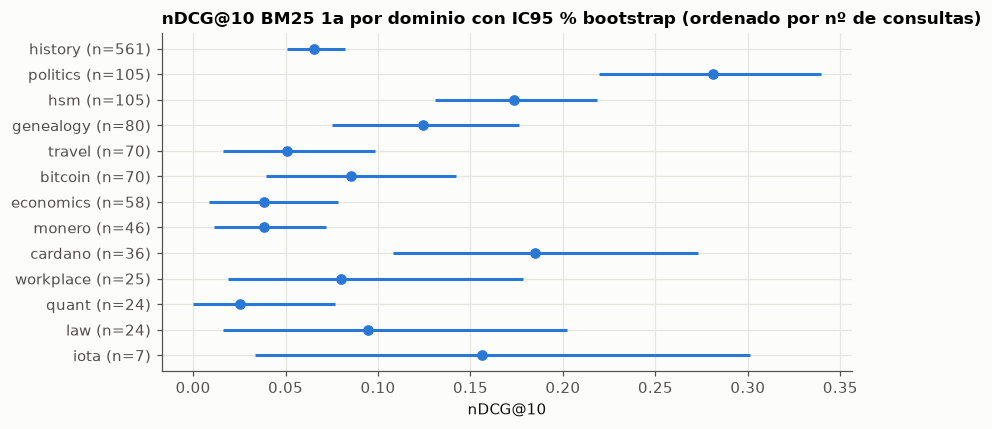

In [25]:
def bootstrap_ci(values: np.ndarray, n_boot: int = 2000, alpha: float = 0.05, seed: int = SEED) -> tuple[float, float]:
    """Intervalo de confianza bootstrap (percentil) para la media.

    Args:
        values: valores por consulta.
        n_boot: número de remuestreos.
        alpha: 1 − nivel de confianza.
        seed: semilla del generador.

    Returns:
        ``(límite inferior, límite superior)``.
    """
    rng = np.random.default_rng(seed)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))


var_rows = []
for dom, g in bm25_1a.groupby("domain"):
    v = g["ndcg_cut_10"].to_numpy()
    lo, hi = bootstrap_ci(v)
    var_rows.append({"dominio": dom, "n": len(v), "nDCG10": v.mean(), "std": v.std(ddof=1),
                     "IC95_inf": lo, "IC95_sup": hi, "ancho_IC": hi - lo})
var_df = pd.DataFrame(var_rows).set_index("dominio").sort_values("n")
display(var_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(var_df))
ax.errorbar(var_df["nDCG10"], y, xerr=[var_df["nDCG10"] - var_df["IC95_inf"], var_df["IC95_sup"] - var_df["nDCG10"]],
            fmt="o", color=C_GOLD, ecolor=C_GOLD, elinewidth=2, capsize=0, ms=6)
ax.set_yticks(y, [f"{d} (n={n})" for d, n in zip(var_df.index, var_df["n"])])
style_ax(ax, "nDCG@10 BM25 1a por dominio con IC95 % bootstrap (ordenado por nº de consultas)", "nDCG@10")
plt.tight_layout(); plt.show()

### 4.6 Revisión manual de consultas fallidas

Se eligen 20 consultas de train con nDCG@10 = 0 en BM25 1a, repartidas entre dominios (ronda por dominio, semilla fija). Para cada una se muestra el título, la clase temporal, la posición del mejor gold, el solapamiento léxico y un fragmento del gold frente al primer documento recuperado.

In [26]:
def pick_failures(per_query: pd.DataFrame, n: int = 20, seed: int = SEED) -> list[tuple[str, str]]:
    """Selecciona ``n`` consultas fallidas (nDCG@10 = 0) repartidas por dominio.

    Recorre los dominios en ronda y toma una consulta al azar de cada uno hasta
    llegar a ``n``, para que no dominen los dominios grandes.

    Returns:
        Lista de tuplas ``(dominio, qid)``.
    """
    rng = random.Random(seed)
    pools = {d: sorted(g.index) for d, g in per_query[per_query["ndcg_cut_10"] == 0].groupby("domain")}
    for p in pools.values():
        rng.shuffle(p)
    picked = []
    while len(picked) < n and any(pools.values()):
        for d in sorted(pools):
            if pools[d] and len(picked) < n:
                picked.append((d, pools[d].pop()))
    return picked


def snippet(text: str, n: int = 260) -> str:
    """Primeros ``n`` caracteres de un texto en una sola línea."""
    return re.sub(r"\s+", " ", text)[:n] + ("…" if len(text) > n else "")


failures = pick_failures(bm25_1a)
guid_idx = guid.set_index("qid")
q_idx = queries.set_index("id")
ranks_idx = ranks.reset_index().rename(columns={"index": "qid"}).set_index("qid")
fail_rows = []
for dom, qid in failures:
    texts = load_texts(dom)
    run = load_run("1a_oficial", dom)[qid]
    top1 = max(run, key=run.get)
    gold = next(g for r in load_examples(dom) if r["id"] == qid for g in r["gold_ids"])
    top1_text = next(d["content"] for d in iter_documents(dom) if d["id"] == top1) if top1 not in texts else texts[top1]
    jac = overlap[(overlap["qid"] == qid) & (overlap["tipo"] == "consulta↔gold")]["jaccard"].max()
    fail_rows.append({"dominio": dom, "qid": qid, "titulo": q_idx.loc[qid, "title"],
                      "clase": guid_idx.loc[qid, "clase_primaria"], "n_gold": q_idx.loc[qid, "n_gold"],
                      "palabras_q": q_idx.loc[qid, "words_clean"], "mejor_rank_gold": ranks_idx.loc[qid, "rank"],
                      "jaccard_max": round(jac, 3), "gold": snippet(texts[gold]), "top1": snippet(top1_text)})
fail_df = pd.DataFrame(fail_rows)
display(fail_df[["dominio", "qid", "titulo", "clase", "n_gold", "palabras_q", "mejor_rank_gold", "jaccard_max"]])

,dominio,qid,titulo,clase,n_gold,palabras_q,mejor_rank_gold,jaccard_max
0,bitcoin,96647_91,What does an orphaned tx look like via rpc?,(vacío),1,114,inf,0.027
1,cardano,9155_105,Downtime when upgrading or restarting a node,event_analysis_and_localization,5,144,82.0,0.096
2,economics,60608_153,"Unit of measure for Eurostat ""Average remuneration of national civil servants""",time_period_contextualization,2,143,inf,0.045
3,genealogy,18137_245,"Finding 1834 location in St Clement, Cornwall, England",event_analysis_and_localization,3,340,36.0,0.113
4,history,69939_314,Did soldiers wear helmets in the 19th century?,time_period_contextualization,4,71,73.0,0.089
5,hsm,18129_674,The origins and development of the Riemannian curvature tensor,origins_evolution_comparative_analysis,3,149,20.0,0.064
6,iota,2497_799,How long do Zero Value Transactions last?,event_analysis_and_localization,5,46,175.0,0.071
7,law,108089_816,Is the 22nd Amendment self-executing?,event_analysis_and_localization,1,310,inf,0.123
8,monero,11152_863,"Received monero, how many confirmations do I need to wait before fully confirmed?",time_period_contextualization,4,57,211.0,0.184
9,politics,93819_910,Do any movements for the restoration of jus soli exist in countries that have eliminated it?,trends_changes_and_cross_period,3,232,129.0,0.105


In [27]:
for r in fail_rows:
    print(f"[{r['dominio']}] {r['qid']} · {r['clase']} · mejor gold en rank {r['mejor_rank_gold']}")
    print(f"  CONSULTA: {r['titulo']}")
    print(f"  GOLD    : {r['gold']}")
    print(f"  TOP-1   : {r['top1']}\n")

[bitcoin] 96647_91 · (vacío) · mejor gold en rank inf
  CONSULTA: What does an orphaned tx look like via rpc?
  GOLD    : The primary effect is felt by the miner who loses the block reward, a built-in economic incentive to stay on the main chain. For users, transactions included in an orphan block are simply returned to the mempool for inclusion in a future block, causing a minor…
  TOP-1   : Mastering Bitcoin Andreas M. Antonopoulos Mastering Bitcoin by Andreas M. Antonopoulos Copyright © 2010 Andreas M. Antonopoulos LLC.. All rights reserved. Printed in the United States of America. Published by O’Reilly Media, Inc., 1005 Gravenstein Highway Nort…

[cardano] 9155_105 · event_analysis_and_localization · mejor gold en rank 82.0
  CONSULTA: Downtime when upgrading or restarting a node
  GOLD    : Mithril is a stake-based multi-signature scheme that leverages the existing Cardano network to provide certified snapshots of all or part of the blockchain state. These snapshots can be useful 

In [28]:
def top10_composition(variant: str = "1a_oficial", split: str = SPLIT) -> pd.DataFrame:
    """Clasifica los documentos del top-10 de BM25 según su formato de ID.

    Sirve para comprobar si los falsos positivos vienen de los documentos de ID largo
    cuyo prefijo es el número de la propia consulta.

    Returns:
        Tabla por dominio con el % de documentos del top-10 de ID corto, de ID largo
        con el mismo número que la consulta y de ID largo con otro número.
    """
    rows = []
    for dom in DOMAINS:
        c = Counter()
        for qid, docs in load_run(variant, dom, split).items():
            for d in sorted(docs, key=docs.get, reverse=True)[:10]:
                info = parse_doc_id(d)
                if info["id_format"] != "largo":
                    c["corto"] += 1
                else:
                    c["largo_mismo_qnum" if info["qnum"] == query_number(qid) else "largo_otro_qnum"] += 1
        rows.append({"dominio": dom, **{k: 100 * v / sum(c.values()) for k, v in c.items()}})
    return pd.DataFrame(rows).set_index("dominio").fillna(0).round(1)


display(Markdown("**Composición del top-10 de BM25 1a (% de documentos) por formato de ID**"))
display(top10_composition())

**Composición del top-10 de BM25 1a (% de documentos) por formato de ID**

,corto,largo_otro_qnum,largo_mismo_qnum
dominio,,,
bitcoin,64.9,32.3,2.9
cardano,79.2,18.6,2.2
economics,81.4,13.1,5.5
genealogy,72.9,21.8,5.4
history,100.0,0.0,0.0
hsm,78.2,14.4,7.4
iota,82.9,10.0,7.1
law,75.8,5.8,18.3
monero,72.2,26.3,1.5


<!-- REVISION_MANUAL -->
**Observaciones de la revisión manual (20 consultas con nDCG@10 = 0):**

1. **El top-1 suele ser relevante aunque no sea gold.** En más de la mitad de los casos, el primer documento contesta la pregunta, a veces mejor que el gold: el texto sobre la "Section 3 of the 14th Amendment" en la consulta sobre la 22ª enmienda (law), "Inflation does not necessarily depend on M1…" (economics), "It's up to you, depending on how risk averse you are…" (monero), "Existing answers are missing critical points. Linking redlining…" (history), o el texto de LinkedIn y referencias (workplace). Varios parecen respuestas del propio hilo de StackExchange. Los qrels son **incompletos**: el gold es un pasaje de *evidencia* concreto, no cualquier texto relevante. Hay que asumir falsos negativos en la evaluación y no sobreajustarse a ellos.
2. **Gold con poca relación léxica (y a veces temática) con la consulta.** "How long do Zero Value Transactions last?" (iota) → gold sobre la degradación del servicio EVM de Shimmer; "Unit of measure for Eurostat…" (economics) → gold sobre ciclos económicos antes de la II Guerra Mundial; "Downtime when upgrading a node" (cardano) → gold sobre Mithril. Ningún retriever léxico los encuentra (rank > 1000 o > 100); requieren razonamiento o conocimiento del dominio.
3. **Documentos basura en las primeras posiciones.** Estado JavaScript serializado (`window.__INITIAL_STATE__`, travel), tablas de Hacker News en markdown (bitcoin), la página de copyright de un libro (bitcoin) y changelogs (cardano). Son textos largos con muchos términos distintos que acumulan score frente a consultas largas.
4. **La señal temporal no se usa.** "Finding 1834 location in St Clement" (genealogy) recupera listas de jueces con fechas; "Did soldiers wear helmets in the 19th century?" (history) recupera una historia genérica de cascos. BM25 trata "1834" o "19th century" como un término más.
5. **Consultas muy largas diluyen el peso de los términos clave** (340 y 539 palabras en dos de los casos). El título casi siempre resume bien la necesidad de información.

La composición del top-10 (celda anterior) muestra que los falsos positivos vienen sobre todo de documentos de ID corto. Los de ID largo con el mismo número que la consulta son solo el 3.7 % del top-10 de BM25 1a en total, aunque llegan al 18 % en `law` y al 12.5 % en `politics`.

<!-- HALLAZGOS -->
## 5. Hallazgos y decisiones para el pipeline

Las cifras son de **train** (salvo la comparación con el paper, sección 3). Los hallazgos sobre los datos están en `eda_track1_tempo.ipynb`, sección 6.

### Baselines
- **El BM25 oficial se reproduce exactamente** (macro 0.1075 en 1a y 0.1024 en 1b; Δ ≤ 0.0001 por dominio).
- **Frente al paper, el macro coincide** (train + dev: 11.0 frente a 10.8 en 1a), pero por dominio hay diferencias de ~2.5 puntos; los datos son los mismos salvo la deduplicación (sección 3.5).
- **La primera etapa es el cuello de botella:** el macro Recall@1000 de BM25 es solo 0.640 (1a) y 0.701 (1b), y 0.33 en `history`. Un reranker sobre BM25 no puede recuperar el ~35 % de gold que no llega al top-1000. El mejor gold queda fuera del top-1000 en el 45 % de las consultas de `history` y en ~30 % de `bitcoin`, `quant` y `travel`.
- **Un encoder denso pequeño mejora mucho a BM25:** BGE-small sin ajuste obtiene en 1a nDCG@10 de 0.261 frente a 0.095 en `law`, 0.151 frente a 0.026 en `quant` y 0.268 frente a 0.156 en `iota`, con Recall@1000 de 0.79–0.99. La fusión RRF con BM25 solo mejora en `iota`: BM25 añade más ruido que señal.
- **Hay mucho ruido en los dominios pequeños:** el IC95 % del nDCG@10 de `iota` (7 consultas) va de 0.03 a 0.30, y el de `law`/`workplace` mide ~0.17–0.19 de ancho. Una mejora de 0.05 en esos dominios no es concluyente.

### Consultas y pasos
- Quitar el HTML sube el BM25 1a de 0.078 a 0.098 con el índice Lucene estándar. **Decisión:** usar siempre consultas limpias y probar variantes título + resumen, o reformulaciones con un LLM.
- **1b: la instrucción sola rinde igual o mejor que la consulta.** Macro nDCG@10: paso 0.110, consulta 0.102, oficial 0.102, limpia+paso 0.111. El paso solo es la mejor variante en 8 de 13 dominios; en los otros 5 (`bitcoin`, `cardano`, `hsm`, `politics`, `travel`) gana la consulta limpia + paso. **Decisión:** combinar ambas señales (fusión de rankings o ponderación) en vez de concatenar texto. (El paper, en cambio, recomienda mantener siempre la consulta junto al paso; con BM25 el efecto es nulo en ambos.)

### Guidance temporal
- **Segmentos más difíciles para BM25:** `materials_artifacts_and_provenance` (0.063), `time_period_contextualization` (0.067), `origins_evolution_comparative_analysis` (0.072) y las intenciones `period_definition` (0.060) y `duration` (0.067). Los más fáciles son `event_analysis_and_localization` (0.137) y la intención `when` (0.140).

### Decisiones para el pipeline
1. **Primera etapa densa con chunking**, empezando por encoders más fuertes que BGE-small (bge-base/large, e5, gte), con FAISS en un proceso aparte de Pyserini. BM25 se queda como señal auxiliar y para comparar.
2. **Preprocesar consultas:** quitar HTML; probar título + inicio del cuerpo y reformulación con LLM o HyDE. En 1b, fusionar los rankings de "paso" y "consulta".
3. **Reranker cross-encoder sobre el top-100 denso**, ajustado con los qrels de train y *hard negatives* minados del propio corpus.
4. **Temporalidad:** usar guidance solo como señal de entrenamiento (p. ej., un clasificador de intención o la generación de consultas) mientras no se confirme que estará en test. Atención especial a las clases de periodo y duración.
5. **Evaluación:** macro por dominio con IC bootstrap; no tomar decisiones con `iota`, `quant` o `law` aisladamente; dev solo al final. Para comparar con el paper, usar train + dev en macro.
6. **No explotar artefactos del ID** ni el orden de los sufijos.

### Preguntas para los organizadores
- ¿Qué campos tendrá el test (¿guidance?, ¿`step_instruction` en 1b?)?
- ¿Tendrá el corpus de test la misma mezcla de IDs cortos y largos? ¿Está permitido usar el formato del ID?
- ¿Profundidad máxima de los rankings en la submission?
- ¿Con qué implementación de BM25 y qué corpus (¿v1.0 o v1.1?) se calcularon las cifras del paper?